<a href="https://colab.research.google.com/github/JonatasYamaguti/4d-modulation-and-artificial-intelligence/blob/main/C%C3%B3digos_IC_Jonatasyamaguti.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Exemplo visual de Fibrações e amostra PSK

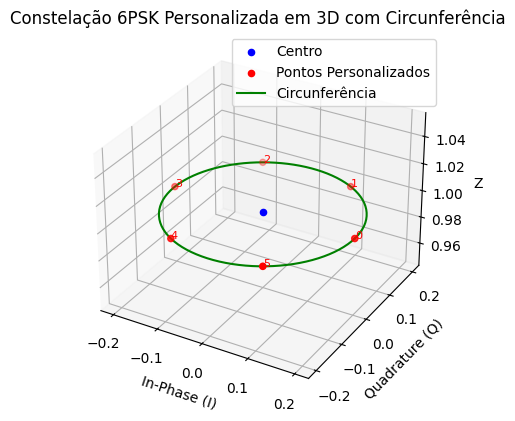

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def generate_custom_6psk_points_on_circle(center, num_points=6, radius=0.2):
    # Gerar coordenadas em um círculo centrado no ponto especificado
    angles = np.linspace(0, 2 * np.pi, num_points, endpoint=False)
    x_custom = center[0] + radius * np.cos(angles)
    y_custom = center[1] + radius * np.sin(angles)
    z_custom = center[2] + np.full_like(x_custom, 0)  # Adicionando uma pequena altura para visualização em 3D

    return x_custom, y_custom, z_custom

def generate_circle_coordinates(center, num_points=100, radius=0.2):
    # Gerar coordenadas para a circunferência
    angles = np.linspace(0, 2 * np.pi, num_points)
    x_circle = center[0] + radius * np.cos(angles)
    y_circle = center[1] + radius * np.sin(angles)
    z_circle = center[2] + np.full_like(x_circle, 0)  # Adicionando uma pequena altura para visualização em 3D

    return x_circle, y_circle, z_circle

def plot_custom_6psk_constellation_3d(x_custom, y_custom, z_custom, center, symbols, x_circle, y_circle, z_circle):
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    ax.scatter(center[0], center[1], center[2], c='blue', marker='o', label='Centro')
    ax.scatter(x_custom, y_custom, z_custom, c='red', marker='o', label='Pontos Personalizados')

    # Anotar os pontos com os símbolos correspondentes
    for i, symbol in enumerate(symbols):
        ax.text(x_custom[i], y_custom[i], z_custom[i], str(symbol), color='red', fontsize=8)

    # Desenhar a circunferência
    ax.plot(x_circle, y_circle, z_circle, color='green', label='Circunferência')

    ax.set_title('Constelação 6PSK Personalizada em 3D com Circunferência')
    ax.set_xlabel('In-Phase (I)')
    ax.set_ylabel('Quadrature (Q)')
    ax.set_zlabel('Z')
    ax.legend()

    plt.show()

# Centro da constelação 6PSK
center = (0, 0, 1)

# Gere pontos personalizados em um círculo centrado no ponto
x_custom, y_custom, z_custom = generate_custom_6psk_points_on_circle(center)

# Gere coordenadas para a circunferência
x_circle, y_circle, z_circle = generate_circle_coordinates(center)

# Plote a constelação 6PSK personalizada em 3D com a circunferência
symbols = np.array([0, 1, 2, 3, 4, 5])
plot_custom_6psk_constellation_3d(x_custom, y_custom, z_custom, center, symbols, x_circle, y_circle, z_circle)

# Fibração de hopf

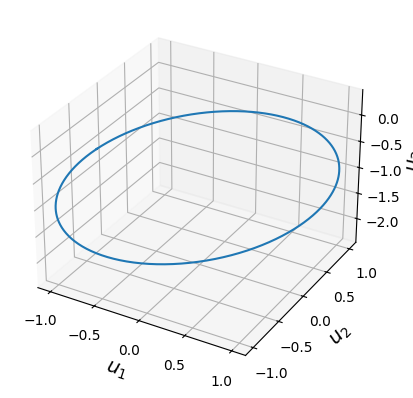

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

tt = np.linspace(0, 2*np.pi, 1000)
theta = np.pi
a = 0
b = np.cos(theta)
c = np.sin(theta)

u1 = np.zeros(len(tt))
u2 = np.zeros(len(tt))
u3 = np.zeros(len(tt))

for j in range(len(tt)):
    # Generate point of Hopf circle in S3
    w = 1/np.sqrt(2*(1+a))*(-np.sin(tt[j]))*(1+a)
    x = 1/np.sqrt(2*(1+a))*(-np.cos(tt[j]))*(1+a)
    y = 1/np.sqrt(2*(1+a))*(b*np.cos(tt[j])+c*np.sin(tt[j]))
    z = 1/np.sqrt(2*(1+a))*(c*np.cos(tt[j])-b*np.sin(tt[j]))

    # Make a stereographic projection onto R3
    u1[j] = 1/(1-w)*x
    u2[j] = 1/(1-w)*y
    u3[j] = 1/(1-w)*z

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot(u1, u2, u3)
ax.set_xlabel('$u_1$', fontsize=14)
ax.set_ylabel('$u_2$', fontsize=14)
ax.set_zlabel('$u_3$', fontsize=14)
plt.show()

# função Hopfmap

In [ ]:
import numpy as np

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001) # cria um vetor de 0 a 2*pi com 2001 colunas
    theta = np.arctan2(b, -a) - phi # pega o arctg(b/-a) e subtrai phi (então é outro vetor de 2001 colunas que a partir de um valor inicial, realiza as 2001 colunas)
    alpha = np.sqrt((1 + c) / 2) # raiz de (1 + cos(theta)/2) --> usa isso pra representar a identidade trigonométrica cos(x)=sqrt((1+cos(2x))/2)
    beta = np.sqrt((1 - c) / 2) # sen(theta/2)

    x = beta * np.cos(phi) # sen(theta/2)*cos(VETOR 0 A 2*PI)
    y = beta * np.sin(phi) # sen(theta/2)*sen(VETOR 0 A 2*PI)
    w = alpha * np.cos(theta) # cos(theta/2)*cos(VETOR arctg x até arctg x - 2*PI)
    z = alpha * np.sin(theta) # cos(theta/2)*sen(VETOR arctg x até arctg x - 2*PI)

    r = np.arccos(w) / np.pi
    # r = 1

    # parametrização
    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz


# função hopfmapponto

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = np.arange(0, 2*np.pi, np.pi/4)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.arange(0, 2*np.pi, np.pi/4)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1], z[:-1], x[:-1], y[:-1]))
    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

print(hopfmapponto)

<function hopfmapponto at 0x7eee9f5a8cc0>


# Esfera 4 ponto ótimos

/tmp/ipython-input-12-271355328.py:24: MatplotlibDeprecationWarning: The plot_date function was deprecated in Matplotlib 3.9 and will be removed in 3.11. Use plot instead.
  ax.plot_date(ponto_x,ponto_y,zs=ponto_z,color="blue")


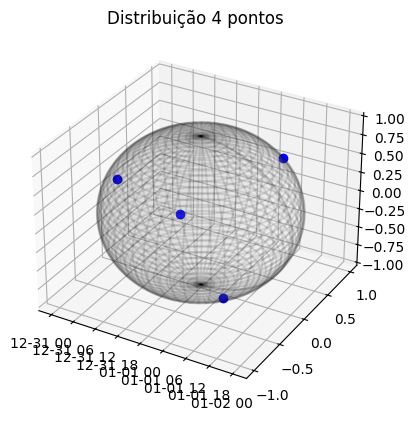

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import style

#coloca o numero de eixos
ax = plt.axes(projection="3d")
# limites theta e fi
theta = np.arange(0,2*np.pi,0.01)
fi = np.arange(0,np.pi,0.01)

theta,fi = np.meshgrid(theta,fi,)
#raio da esfera
r = 1
# criando as coordenadas
x = r * np.sin(fi) * np.cos(theta)
y = r * np.sin(fi) * np.sin(theta)
z = r * np.cos(fi)
ponto_x= np.array([0.5774,0.5774,-0.5774,-0.5774])
ponto_y= np.array([0.5774,-0.5774,0.5774,-0.5774])
ponto_z= np.array([0.5774,-0.5774,-0.5774,0.5774])

ax.plot_surface(x, y ,z,color="white", alpha = 0.1 )
ax.plot_wireframe(x, y ,z, color="black", alpha = 0.1 )
ax.plot_date(ponto_x,ponto_y,zs=ponto_z,color="blue")
plt.title("Distribuição 4 pontos")
plt.show()


# esfera 6 pontos

/tmp/ipython-input-13-1306804824.py:24: MatplotlibDeprecationWarning: The plot_date function was deprecated in Matplotlib 3.9 and will be removed in 3.11. Use plot instead.
  ax.plot_date(ponto_x,ponto_y,zs=ponto_z,color="blue")


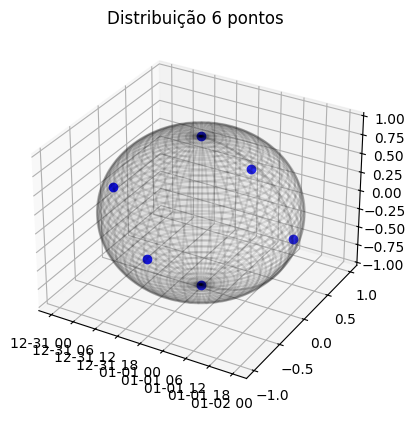

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import style

#coloca o numero de eixos
ax = plt.axes(projection="3d")
# limites theta e fi
theta = np.arange(0,2*np.pi,0.01)
fi = np.arange(0,np.pi,0.01)

theta,fi = np.meshgrid(theta,fi,)
#raio da esfera
r = 1
# criando as coordenadas
x = r * np.sin(fi) * np.cos(theta)
y = r * np.sin(fi) * np.sin(theta)
z = r * np.cos(fi)
ponto_x= np.array([0,0,1,-1,0,0])
ponto_y= np.array([0,0,0,0,1,-1])
ponto_z= np.array([1,-1,0,0,0,0])

ax.plot_surface(x, y ,z,color="white", alpha = 0.1 )
ax.plot_wireframe(x, y ,z, color="black", alpha = 0.1 )
ax.plot_date(ponto_x,ponto_y,zs=ponto_z,color="blue")
plt.title("Distribuição 6 pontos")
plt.show()

# esfera 8 pontos

/tmp/ipykernel_194/924762906.py:26: MatplotlibDeprecationWarning: The plot_date function was deprecated in Matplotlib 3.9 and will be removed in 3.11. Use plot instead.
  ax.plot_date(ponto_x,ponto_y,zs=ponto_z,color="blue")


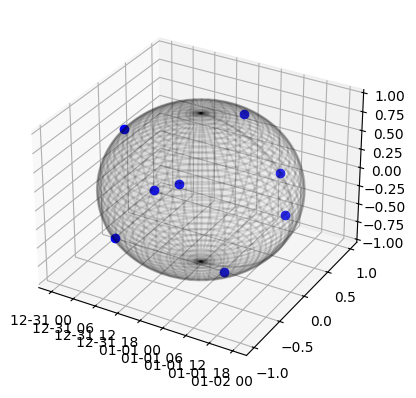

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import style

#coloca o numero de eixos
ax = plt.axes(projection="3d")
# limites theta e fi
theta = np.arange(0,2*np.pi,0.01)
fi = np.arange(0,np.pi,0.01)

theta,fi = np.meshgrid(theta,fi,)
#raio da esfera
r = 1
# criando as coordenadas
x = r * np.sin(fi) * np.cos(theta)
y = r * np.sin(fi) * np.sin(theta)
z = r * np.cos(fi)
ponto_x= np.array([0.6078,-0.6078,0.6078,-0.6078,0.8595,-0.8595,0,0])
ponto_y= np.array([0.6078,0.6078,-0.6078,-0.6078,0,0,0.8595,-0.8595])
ponto_z= np.array([-0.5111,-0.5111,-0.5111,-0.5111,0.5111,0.5111,0.5111,0.5111])

#0.6078,0.8595, 0.5111)

ax.plot_surface(x, y ,z,color="white", alpha = 0.1 )
ax.plot_wireframe(x, y ,z, color="black", alpha = 0.1 )
ax.plot_date(ponto_x,ponto_y,zs=ponto_z,color="blue")
plt.title("")
plt.show()

# esfera 12 pontos

/tmp/ipython-input-1302711878.py:26: MatplotlibDeprecationWarning: The plot_date function was deprecated in Matplotlib 3.9 and will be removed in 3.11. Use plot instead.
  ax.plot_date(ponto_x,ponto_y,zs=ponto_z,color="blue")


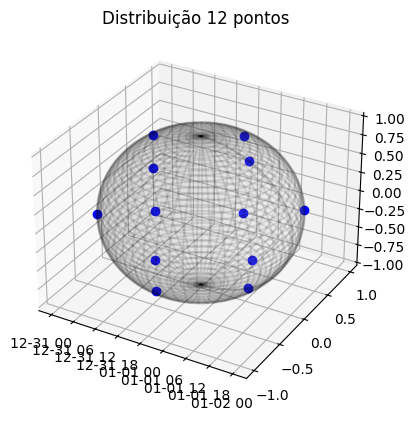

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import style

#coloca o numero de eixos
ax = plt.axes(projection="3d")
# limites theta e fi
theta = np.arange(0,2*np.pi,0.01)
fi = np.arange(0,np.pi,0.01)

theta,fi = np.meshgrid(theta,fi,)
#raio da esfera
r = 1
# criando as coordenadas
x = r * np.sin(fi) * np.cos(theta)
y = r * np.sin(fi) * np.sin(theta)
z = r * np.cos(fi)
ponto_x= np.array([0,0,0,0, 0.5257, 0.5257,- 0.5257,- 0.5257,0.8506,0.8506,-0.8506,-0.8506])
ponto_y= np.array([0.8506,0.8506,-0.8506,-0.8506,0,0,0,0,0.5257,-0.5257,0.5257,-0.5257])
ponto_z= np.array([0.5257,-0.5257,0.5257,-0.5257,0.8506,-0.8506,0.8506,-0.8506,0,0,0,0])



ax.plot_surface(x, y ,z,color="white", alpha = 0.1 )
ax.plot_wireframe(x, y ,z, color="black", alpha = 0.1 )
ax.plot_date(ponto_x,ponto_y,zs=ponto_z,color="blue")
plt.title("Distribuição 12 pontos")
plt.show()

#0.8506, 0.5257

# esfera 16 pontos

/tmp/ipython-input-2492533534.py:26: MatplotlibDeprecationWarning: The plot_date function was deprecated in Matplotlib 3.9 and will be removed in 3.11. Use plot instead.
  ax.plot_date(ponto_x,ponto_y,zs=ponto_z,color="blue")


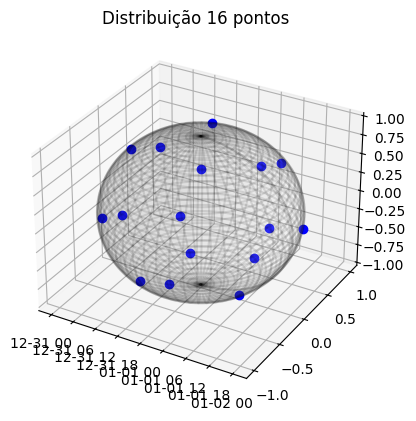

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import style

#coloca o numero de eixos
ax = plt.axes(projection="3d")
# limites theta e fi
theta = np.arange(0,2*np.pi,0.01)
fi = np.arange(0,np.pi,0.01)

theta,fi = np.meshgrid(theta,fi,)
#raio da esfera
r = 1
# criando as coordenadas
x = r * np.sin(fi) * np.cos(theta)
y = r * np.sin(fi) * np.sin(theta)
z = r * np.cos(fi)
ponto_x= np.array([0.3529, -0.3910, 0.6234,-0.8731, 0.2464, -0.2874, -0.4980, -0.9249,0.5242, 0.9385,0.1946, -0.6495, 0.4047, 0.8594,-0.2083,-0.3119,])
ponto_y= np.array([ 0.7499,-0.5093,0.0565,0.1507,-0.8105,-0.2701,0.8623,0.0311, -0.1725,0.3291,-0.9301, -0.7462,0.8695, -0.5109,0.5699,0.3307 ])
ponto_z= np.array([ -0.5596, -0.7666, 0.7799, 0.4637, 0.5313, 0.9189, -0.0917, -0.3790, -0.8339, -0.1044, -0.3114, 0.1458, 0.2832, 0.0197, 0.7949, -0.8907  ])



ax.plot_surface(x, y ,z,color="white", alpha = 0.1 )
ax.plot_wireframe(x, y ,z, color="black", alpha = 0.1 )
ax.plot_date(ponto_x,ponto_y,zs=ponto_z,color="blue")
plt.title("Distribuição 16 pontos")
plt.show()

#4Pol-8PSK Somente pontos

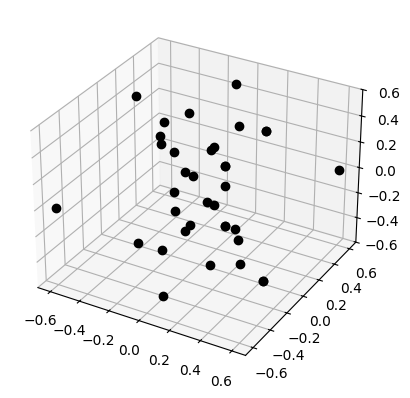

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = np.linspace(0, 2*np.pi, 9)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.linspace(0, 2*np.pi, 9)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1][:4], z[:-1][:4], x[:-1][:4], y[:-1][:4]))
    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

coord = np.array([[0, 0, 0, 0]])
ponto = np.array([[0, 0, 0, 0]])

t = 11*np.pi/36
p = np.pi/4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fig = plt.figure(5)
ax = fig.add_subplot(111, projection='3d')

fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2,)
plt.axis('equal')

t = 11*np.pi/36
p = -np.pi/4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2,)

t = -11*np.pi/36
p = np.pi/4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2,)

t = -11*np.pi/36
p = -np.pi/4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2,)

plt.show()

# 4Pol-8PSK Somente circulos

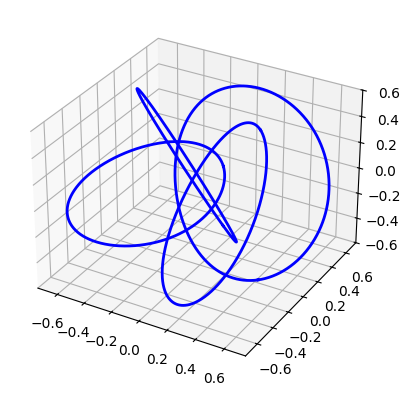

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

t = 11*np.pi/36
p = np.pi/4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fig = plt.figure(5)
ax = fig.add_subplot(111, projection='3d')

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'b', linewidth=2)
plt.axis('equal')

t = 11*np.pi/36
p = -np.pi/4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'b', linewidth=2)

t = -11*np.pi/36
p = np.pi/4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'b', linewidth=2)

t = -11*np.pi/36
p = -np.pi/4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'b', linewidth=2)

plt.show()

# 4Pol-8PSK Circulos e Pontos

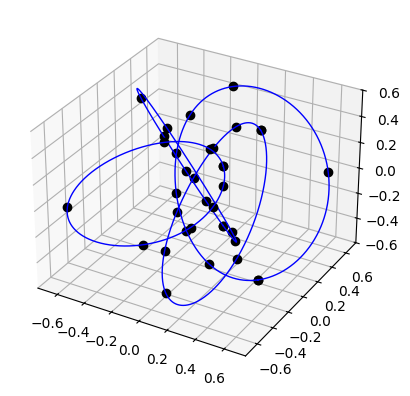

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = np.linspace(0, 2*np.pi, 9)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.linspace(0, 2*np.pi, 9)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1][:4], z[:-1][:4], x[:-1][:4], y[:-1][:4]))
    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

coord = np.array([[0, 0, 0, 0]])
ponto = np.array([[0, 0, 0, 0]])

t = 11*np.pi/36
p = np.pi/4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fig = plt.figure(5)
ax = fig.add_subplot(111, projection='3d')

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)
plt.axis('equal')

t = 11*np.pi/36
p = -np.pi/4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)

t = -11*np.pi/36
p = np.pi/4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)

t = -11*np.pi/36
p = -np.pi/4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)

plt.show()

# 6Pol- 8PSK somente pontos

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = np.linspace(0, 2*np.pi, 9)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.linspace(0, 2*np.pi, 9)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1][:4], z[:-1][:4], x[:-1][:4], y[:-1][:4]))
    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

coord = np.array([[0, 0, 0, 0]])
ponto = np.array([[0, 0, 0, 0]])

t = 0
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

fx, fy, fz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ob', linewidth=2)

t = np.pi
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ob', linewidth=2)

t = np.pi / 2
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'og', linewidth=2)

t = np.pi / 2
p = np.pi / 2
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'or', linewidth=2)

t = np.pi / 2
p = np.pi
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'og', linewidth=2)

t = np.pi / 2
p = 3 * np.pi / 2
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'or', linewidth=2)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Hopf Map')
ax.grid(True)
plt.show()


# 6Pol- 8PSK somente circulos

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz


t = 0
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'b', linewidth=2)

t = np.pi
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'b', linewidth=2)

t = np.pi / 2
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'g', linewidth=2)

t = np.pi / 2
p = np.pi / 2
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'r', linewidth=2)

t = np.pi / 2
p = np.pi
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'g', linewidth=2)

t = np.pi / 2
p = 3 * np.pi / 2
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'r', linewidth=2)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Hopf Map')
ax.grid(True)
plt.show()


# 6Pol- 8PSK circulos e pontos

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = phi = np.linspace(0, 2*np.pi, 9)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.arange(0, 2*np.pi, np.pi/4)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1][:4], z[:-1][:4], x[:-1][:4], y[:-1][:4]))

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

coord = np.array([[0, 0, 0, 0]])
ponto = np.array([[0, 0, 0, 0]])

t = 0
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)

t = np.pi
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)

t = np.pi / 2
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'g', linewidth=1)

t = np.pi / 2
p = np.pi / 2
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'r', linewidth=1)

t = np.pi / 2
p = np.pi
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'g', linewidth=1)

t = np.pi / 2
p = 3 * np.pi / 2
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'r', linewidth=1)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Hopf Map')
ax.grid(True)
plt.show()


# 8pol - 8PSk somente circulos

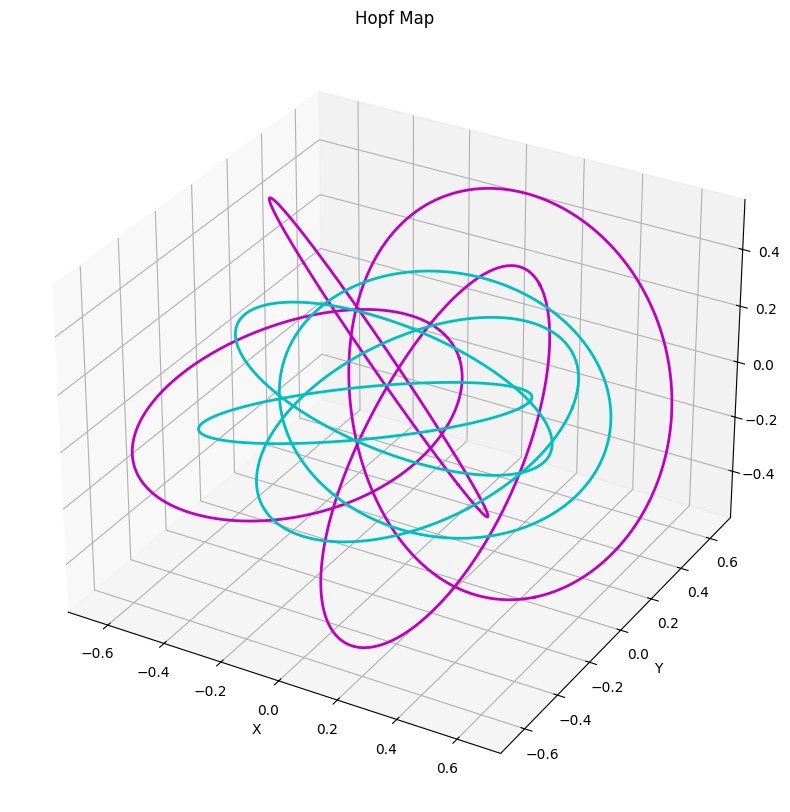

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

t = np.pi / 3
p = np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'm', linewidth=2)
p = 3 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'm', linewidth=2)

p = 5 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'm', linewidth=2)

p = 7 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'm', linewidth=2)

t = 3 * np.pi / 4
p = np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'c', linewidth=2)

p = 3 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'c', linewidth=2)

p = 5 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'c', linewidth=2)

p = 7 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'c', linewidth=2)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Hopf Map')
ax.grid(True)
plt.show()




# 8pol - 8PSk somente pontos

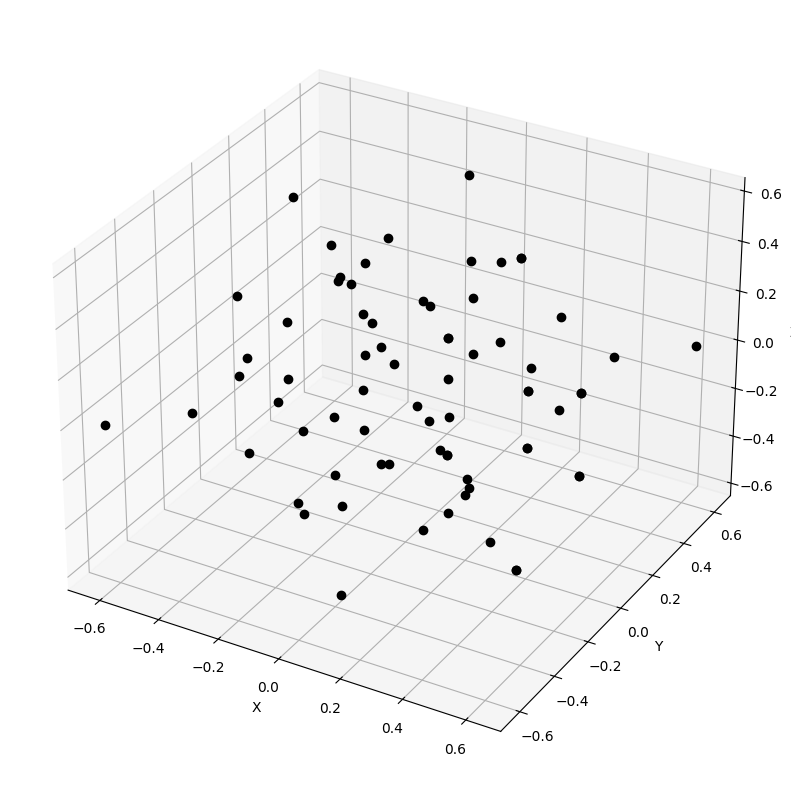

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = np.linspace(0, 2*np.pi, 9)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.linspace(0, 2*np.pi, 9)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1][:4], z[:-1][:4], x[:-1][:4], y[:-1][:4]))
    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

coord = np.array([[0, 0, 0, 0]])
ponto = np.array([[0, 0, 0, 0]])

t = np.pi / 4
p = np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')


fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2,)


p = 3 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)


fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)


p = 5 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)


fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)

p = 7 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)


fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)


t = 3 * np.pi / 4
p = np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)


fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)


p = 3 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)


fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)


p = 5 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)


fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)


p = 7 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)


fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('')
ax.grid(True)
plt.show()


# 8Pol- 8PSK circulos e pontos

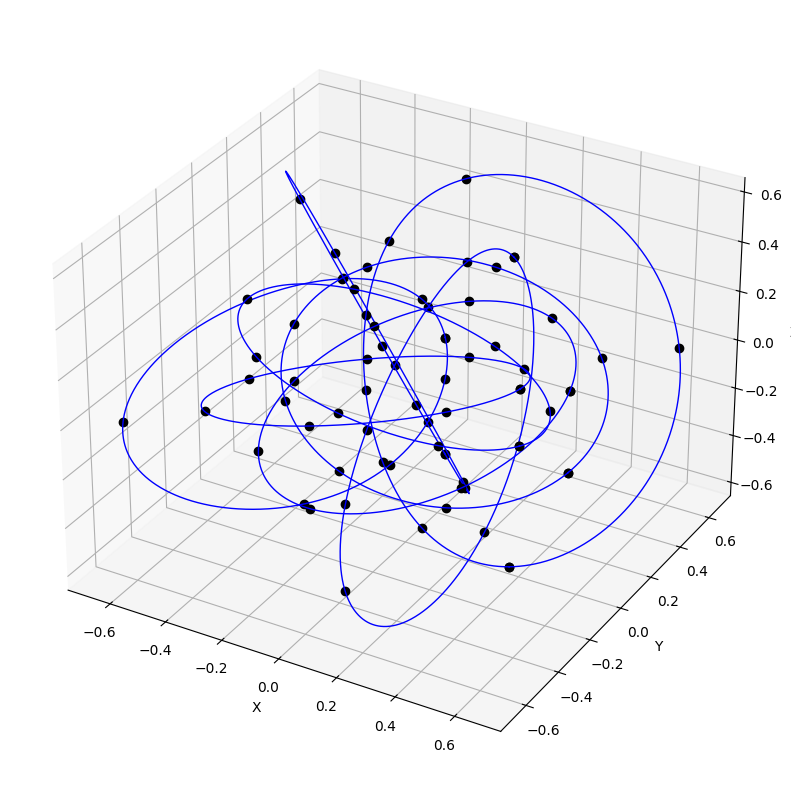

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = np.linspace(0, 2*np.pi, 9)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.linspace(0, 2*np.pi, 9)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1][:4], z[:-1][:4], x[:-1][:4], y[:-1][:4]))
    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

coord = np.array([[0, 0, 0, 0]])
ponto = np.array([[0, 0, 0, 0]])

t = np.pi / 4
p = np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)

p = 3 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)

p = 5 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)
p = 7 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)

t = 3 * np.pi / 4
p = np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)

p = 3 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)

p = 5 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)

p = 7 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('')
ax.grid(True)
plt.show()

# 12 Pol - 8PSK somente circulos

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = np.linspace(0, 2*np.pi, 9)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.arange(0, 2*np.pi, np.pi/4)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1][:4], z[:-1][:4], x[:-1][:4], y[:-1][:4]))

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

coord = np.array([[0, 0, 0, 0]])
ponto = np.array([[0, 0, 0, 0]])

# Definição dos ângulos em radianos
angulos = [
    (np.pi / 2, np.pi / 6),
    (np.pi / 2, -np.pi / 6),
    (-np.pi / 2, np.pi / 6),
    (-np.pi / 2, -np.pi / 6),
    (0, np.pi / 3),
    (0, -np.pi / 3),
    (np.pi, np.pi / 3),
    (np.pi, -np.pi / 3),
    (0.5533, 0),
    (-0.5533, 0),
    (2.5862, 0),
    (-2.5862, 0)
]

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

for t, p in angulos:
    a = np.sin(t) * np.cos(p)
    b = np.sin(t) * np.sin(p)
    c = np.cos(t)

    fxx, fyy, fzz = hopfmap(a, b, c)
    ax.plot3D(fxx, fyy, fzz, linewidth=1)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Hopf Map')
ax.grid(True)
plt.show()


# 12 Pol - 8PSK somente pontos

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = np.linspace(0, 2*np.pi, 9)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.arange(0, 2*np.pi, np.pi/4)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1][:4], z[:-1][:4], x[:-1][:4], y[:-1][:4]))

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

coord = np.array([[0, 0, 0, 0]])
ponto = np.array([[0, 0, 0, 0]])

# Definição dos ângulos em radianos
angulos = [
    (np.pi / 2, np.pi / 6),
    (np.pi / 2, -np.pi / 6),
    (-np.pi / 2, np.pi / 6),
    (-np.pi / 2, -np.pi / 6),
    (0, np.pi / 3),
    (0, -np.pi / 3),
    (np.pi, np.pi / 3),
    (np.pi, -np.pi / 3),
    (0.5533, 0),
    (-0.5533, 0),
    (2.5862, 0),
    (-2.5862, 0)
]

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

for t, p in angulos:
    a = np.sin(t) * np.cos(p)
    b = np.sin(t) * np.sin(p)
    c = np.cos(t)


    fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
    ax.plot3D(fx, fy, fz, 'ok', linewidth=2)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Hopf Map')
ax.grid(True)
plt.show()


# 12 Pol - 8PSK circulos e pontos

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = np.linspace(0, 2*np.pi, 9)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.arange(0, 2*np.pi, np.pi/4)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1][:4], z[:-1][:4], x[:-1][:4], y[:-1][:4]))

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

coord = np.array([[0, 0, 0, 0]])
ponto = np.array([[0, 0, 0, 0]])

# Definição dos ângulos em radianos
angulos = [
    (np.pi / 2, np.pi / 6),
    (np.pi / 2, -np.pi / 6),
    (-np.pi / 2, np.pi / 6),
    (-np.pi / 2, -np.pi / 6),
    (0, np.pi / 3),
    (0, -np.pi / 3),
    (np.pi, np.pi / 3),
    (np.pi, -np.pi / 3),
    (0.5533, 0),
    (-0.5533, 0),
    (2.5862, 0),
    (-2.5862, 0)
]

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

for t, p in angulos:
    a = np.sin(t) * np.cos(p)
    b = np.sin(t) * np.sin(p)
    c = np.cos(t)

    fxx, fyy, fzz = hopfmap(a, b, c)
    fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
    ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
    ax.plot3D(fxx, fyy, fzz, linewidth=1)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Hopf Map')
ax.grid(True)
plt.show()


# 14Pol- 8PSK circulos

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

t = 0
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fig = plt.figure(5)
ax = fig.add_subplot(111, projection='3d')

fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'b', linewidth=2)
plt.axis('equal')

t = np.pi
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'b', linewidth=2)

t = np.pi / 2
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'g', linewidth=2)

t = np.pi / 2
p = np.pi / 2
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'r', linewidth=2)

t = np.pi / 2
p = np.pi
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'g', linewidth=2)

t = np.pi / 2
p = 3 * np.pi / 2
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'r', linewidth=2)

t = np.pi / 4
p = np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'm', linewidth=2)

t = np.pi / 4
p = 3 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'm', linewidth=2)

t = np.pi / 4
p = 5 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'm', linewidth=2)

t = np.pi / 4
p = 7 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'm', linewidth=2)

t = 3 * np.pi / 4
p = np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'c', linewidth=2)

t = 3 * np.pi / 4
p = 3 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'c', linewidth=2)

t = 3 * np.pi / 4
p = 5 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'c', linewidth=2)

t = 3 * np.pi / 4
p = 7 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz = hopfmap(a, b, c)
ax.plot3D(fx, fy, fz, 'c', linewidth=2)

plt.show()


# 14Pol- 8PSK pontos

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = np.linspace(0, 2*np.pi, 9)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.linspace(0, 2*np.pi, 9)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1][:4], z[:-1][:4], x[:-1][:4], y[:-1][:4]))
    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

coord = np.array([[0, 0, 0, 0]])
ponto = np.array([[0, 0, 0, 0]])
t = 0
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fig = plt.figure(7)
ax = fig.add_subplot(111, projection='3d')

fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 1)
ax.plot3D(fx, fy, fz, 'ob', linewidth=2,)

t = np.pi
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 2)
ax.plot3D(fx, fy, fz, 'ob', linewidth=2)

t = np.pi / 2
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 3)
ax.plot3D(fx, fy, fz, 'og', linewidth=2)

t = np.pi / 2
p = np.pi / 2
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 4)
ax.plot3D(fx, fy, fz, 'or', linewidth=2)

t = np.pi / 2
p = np.pi
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 5)
ax.plot3D(fx, fy, fz, 'og', linewidth=2)

t = np.pi / 2
p = 3 * np.pi / 2
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 6)
ax.plot3D(fx, fy, fz, 'or', linewidth=2)

t = np.pi / 4
p = np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 7)
ax.plot3D(fx, fy, fz, 'om', linewidth=2)

t = np.pi / 4
p = 3 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 8)
ax.plot3D(fx, fy, fz, 'om', linewidth=2)

t = np.pi / 4
p = 5 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 9)
ax.plot3D(fx, fy, fz, 'om', linewidth=2)

t = np.pi / 4
p = 7 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 10)
ax.plot3D(fx, fy, fz, 'om', linewidth=2)

t = 3 * np.pi / 4
p = np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 11)
ax.plot3D(fx, fy, fz, 'oc', linewidth=2)

t = 3 * np.pi / 4
p = 3 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 12)
ax.plot3D(fx, fy, fz, 'oc', linewidth=2)

t = 3 * np.pi / 4
p = 5 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 13)
ax.plot3D(fx, fy, fz, 'oc', linewidth=2)

t = 3 * np.pi / 4
p = 7 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 14)
ax.plot3D(fx, fy, fz, 'oc', linewidth=2)

plt.show()



# 14Pol- 8PSK circulos e pontos

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = np.linspace(0, 2*np.pi, 9)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.linspace(0, 2*np.pi, 9)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1][:4], z[:-1][:4], x[:-1][:4], y[:-1][:4]))
    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

coord = np.array([[0, 0, 0, 0]])
ponto = np.array([[0, 0, 0, 0]])

t = 0
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)

fig = plt.figure(6)
ax = fig.add_subplot(111, projection='3d')

fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 1)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=2)

t = np.pi
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 2)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'b', linewidth=2)

t = np.pi / 2
p = 0
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 3)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'g', linewidth=2)

t = np.pi / 2
p = np.pi / 2
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 4)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'r', linewidth=2)

t = np.pi / 2
p = np.pi
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 5)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'g', linewidth=2)

t = np.pi / 2
p = 3 * np.pi / 2
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 6)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'r', linewidth=2)

t = np.pi / 4
p = np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 7)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'm', linewidth=2)

t = np.pi / 4
p = 3 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 8)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'm', linewidth=2)

t = np.pi / 4
p = 5 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 9)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'm', linewidth=2)

t = np.pi / 4
p = 7 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 10)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'm', linewidth=2)

t = 3 * np.pi / 4
p = np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 11)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'c', linewidth=2)

t = 3 * np.pi / 4
p = 3 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 12)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'c', linewidth=2)

t = 3 * np.pi / 4
p = 5 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 13)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'c', linewidth=2)

t = 3 * np.pi / 4
p = 7 * np.pi / 4
a = np.sin(t) * np.cos(p)
b = np.sin(t) * np.sin(p)
c = np.cos(t)
fxx, fyy, fzz = hopfmap(a, b, c)
fx, fy, fz, coord = hopfmapponto(a, b, c, coord, 14)
ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
ax.plot3D(fxx, fyy, fzz, 'c', linewidth=2)

plt.show()

# 16Pol - 8PSK somente circulos

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = phi = np.linspace(0, 2*np.pi, 9)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.arange(0, 2*np.pi, np.pi/4)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1][:4], z[:-1][:4], x[:-1][:4], y[:-1][:4]))

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

coord = np.array([[0, 0, 0, 0]])
ponto = np.array([[0, 0, 0, 0]])

# Definindo os pontos fornecidos
pontos = [
    (64.79850840166546, -34.0273546499453),
    (-127.51418474902081, -50.051493765255515),
    (5.178683528378084, 51.24914243330866),
    (170.20704506348693, 27.62564405473258),
    (-73.09021049876911, 32.09507739364499),
    (-136.7773973203163, 66.77046871697847),
    (120.00751752697788, -5.261482519429743),
    (178.07414031197533, -22.27118836981608),
    (-18.21497298396402, -56.50445440345031),
    (19.32403157344163, -5.9926339285291315),
    (-78.1827663949982, -18.1443241566906),
    (-131.03663970759357, 8.38393609421238),
    (65.0408519747274, 16.45116058852462),
    (-30.730828166354602, 1.1288138424155816),
    (110.07749550739264, 52.644276053930724),
    (133.32422425973482, -62.961868971692354)
]

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

# Adicionando os pontos fornecidos
for theta_deg, phi_deg in pontos:
    theta_rad = np.radians(theta_deg)
    phi_rad = np.radians(phi_deg)

    t = theta_rad
    p = phi_rad
    a = np.sin(t) * np.cos(p)
    b = np.sin(t) * np.sin(p)
    c = np.cos(t)

    fxx, fyy, fzz = hopfmap(a, b, c)

    ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Hopf Map')
ax.grid(True)
plt.show()


# 16Pol - 8PSK somente pontos

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = phi = np.linspace(0, 2*np.pi, 9)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.arange(0, 2*np.pi, np.pi/4)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1][:4], z[:-1][:4], x[:-1][:4], y[:-1][:4]))

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

coord = np.array([[0, 0, 0, 0]])
ponto = np.array([[0, 0, 0, 0]])

# Definindo os pontos fornecidos
pontos = [
    (64.79850840166546, -34.0273546499453),
    (-127.51418474902081, -50.051493765255515),
    (5.178683528378084, 51.24914243330866),
    (170.20704506348693, 27.62564405473258),
    (-73.09021049876911, 32.09507739364499),
    (-136.7773973203163, 66.77046871697847),
    (120.00751752697788, -5.261482519429743),
    (178.07414031197533, -22.27118836981608),
    (-18.21497298396402, -56.50445440345031),
    (19.32403157344163, -5.9926339285291315),
    (-78.1827663949982, -18.1443241566906),
    (-131.03663970759357, 8.38393609421238),
    (65.0408519747274, 16.45116058852462),
    (-30.730828166354602, 1.1288138424155816),
    (110.07749550739264, 52.644276053930724),
    (133.32422425973482, -62.961868971692354)
]

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

# Adicionando os pontos fornecidos
for theta_deg, phi_deg in pontos:
    theta_rad = np.radians(theta_deg)
    phi_rad = np.radians(phi_deg)

    t = theta_rad
    p = phi_rad
    a = np.sin(t) * np.cos(p)
    b = np.sin(t) * np.sin(p)
    c = np.cos(t)


    fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
    ax.plot3D(fx, fy, fz, 'ok', linewidth=2)


ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Hopf Map')
ax.grid(True)
plt.show()


# 16Pol - 8PSK circulos e pontos

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

def hopfmapponto(a, b, c, coord, ponto):
    if a == 0 and b == 0 and c == 1:
        phi = phi = np.linspace(0, 2*np.pi, 9)
        for i in range(9):
            if phi[i] == 0 or phi[i] == 2*np.pi:
                phi[i] = phi[i] - np.pi/1000
        theta = np.arctan2(b, -a) - phi
    else:
        phi = np.arange(0, 2*np.pi, np.pi/4)
        theta = np.arctan2(b, -a) - phi

    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    coord = np.vstack((coord, w[:-1][:4], z[:-1][:4], x[:-1][:4], y[:-1][:4]))

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz, coord

coord = np.array([[0, 0, 0, 0]])
ponto = np.array([[0, 0, 0, 0]])

# Definindo os pontos fornecidos
pontos = [
    (64.79850840166546, -34.0273546499453),
    (-127.51418474902081, -50.051493765255515),
    (5.178683528378084, 51.24914243330866),
    (170.20704506348693, 27.62564405473258),
    (-73.09021049876911, 32.09507739364499),
    (-136.7773973203163, 66.77046871697847),
    (120.00751752697788, -5.261482519429743),
    (178.07414031197533, -22.27118836981608),
    (-18.21497298396402, -56.50445440345031),
    (19.32403157344163, -5.9926339285291315),
    (-78.1827663949982, -18.1443241566906),
    (-131.03663970759357, 8.38393609421238),
    (65.0408519747274, 16.45116058852462),
    (-30.730828166354602, 1.1288138424155816),
    (110.07749550739264, 52.644276053930724),
    (133.32422425973482, -62.961868971692354)
]

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

# Adicionando os pontos fornecidos
for theta_deg, phi_deg in pontos:
    theta_rad = np.radians(theta_deg)
    phi_rad = np.radians(phi_deg)

    t = theta_rad
    p = phi_rad
    a = np.sin(t) * np.cos(p)
    b = np.sin(t) * np.sin(p)
    c = np.cos(t)

    fxx, fyy, fzz = hopfmap(a, b, c)
    fx, fy, fz, coord = hopfmapponto(a, b, c, coord, ponto)
    ax.plot3D(fx, fy, fz, 'ok', linewidth=2)
    ax.plot3D(fxx, fyy, fzz, 'b', linewidth=1)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Hopf Map')
ax.grid(True)
plt.show()

#QAM 4 Pontos

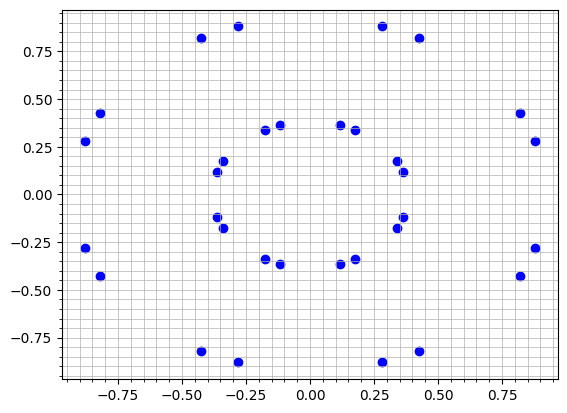

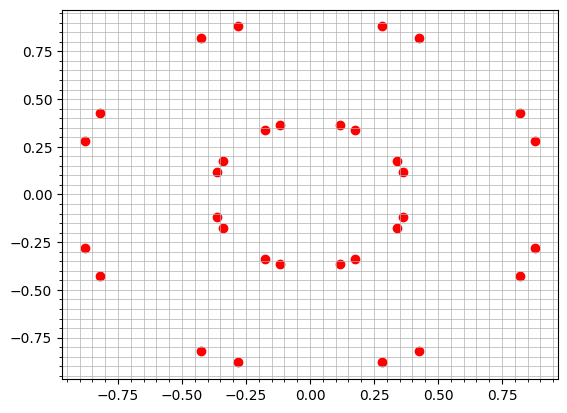

[np.float64(0.8804762392171493), np.float64(0.4247082002778669), np.float64(-0.2798481423331213), np.float64(-0.8204732385702832), np.float64(-0.8804762392171495), np.float64(-0.42470820027786715), np.float64(0.279848142333121), np.float64(0.8204732385702831), np.float64(0.8804762392171493), np.float64(0.8204732385702833), np.float64(0.2798481423331214), np.float64(-0.424708200277867), np.float64(-0.8804762392171493), np.float64(-0.8204732385702833), np.float64(-0.2798481423331213), np.float64(0.4247082002778669), np.float64(0.36470519963100095), np.float64(0.3398511429799874), np.float64(0.11591689595929518), np.float64(-0.17591989660616122), np.float64(-0.36470519963100095), np.float64(-0.3398511429799874), np.float64(-0.11591689595929514), np.float64(0.17591989660616117), np.float64(0.36470519963100095), np.float64(0.17591989660616117), np.float64(-0.11591689595929514), np.float64(-0.33985114297998736), np.float64(-0.36470519963100095), np.float64(-0.1759198966061613), np.float64(0.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

X1 = []
X2 = []
X3 = []
X4 = []



theta_vals = [0.7853981633974483,-0.7853981633974483,2.356194490192345,-2.356194490192345]
phi_vals = [0.6154797086703874,-0.6154797086703874,-0.6154797086703874,0.6154797086703874]
varphi_vals = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi, 5*np.pi/4, 3*np.pi/2, 7*np.pi/4]

count = 0
for n in range(len(theta_vals)):
    theta = theta_vals[n]
    phi = phi_vals[n]
    for varphi in varphi_vals:
        count += 1
        X1.append(np.cos(theta/2) * np.cos(varphi + phi/2))
        X2.append(np.cos(theta/2) * np.sin(varphi + phi/2))
        X3.append(np.sin(theta/2) * np.cos(varphi - phi/2))
        X4.append(np.sin(theta/2) * np.sin(varphi - phi/2))


plt.figure(20)
plt.scatter(X1, X2, color='b')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()

plt.figure(21)
plt.scatter(X3, X4, color='r')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()

plt.show()

print(X1)

print('X1 =', np.shape(X1))
print('X2 =', np.shape(X2))
print('X3 =', np.shape(X3))
print('X4 =', np.shape(X4))

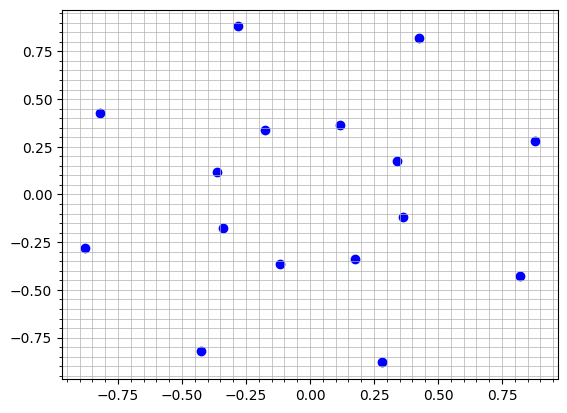

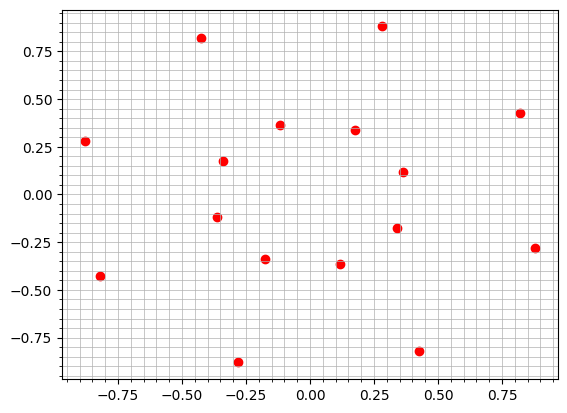

[np.float64(0.8804762392171493), np.float64(0.4247082002778669), np.float64(-0.2798481423331213), np.float64(-0.8204732385702832), np.float64(-0.8804762392171495), np.float64(-0.42470820027786715), np.float64(0.279848142333121), np.float64(0.8204732385702831), np.float64(0.36470519963100095), np.float64(0.3398511429799874), np.float64(0.11591689595929518), np.float64(-0.17591989660616122), np.float64(-0.36470519963100095), np.float64(-0.3398511429799874), np.float64(-0.11591689595929514), np.float64(0.17591989660616117)]
X1 = (16,)
X2 = (16,)
X3 = (16,)
X4 = (16,)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

X1 = []
X2 = []
X3 = []
X4 = []



theta_vals1 = [0.7853981633974483, 2.356194490192345]
phi_vals1 = [0.6154797086703874,-0.6154797086703874]
theta_vals2 = [-0.7853981633974483 ,-2.356194490192345]
phi_vals2 = [-0.6154797086703874,0.6154797086703874]
varphi_vals = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi, 5*np.pi/4, 3*np.pi/2, 7*np.pi/4]

# MODO CORRETO PARA 32 PONTOS
for theta, phi in zip(theta_vals1, phi_vals1):
    for varphi in varphi_vals:
        X1.append(np.cos(theta/2) * np.cos(varphi + phi/2))
        X2.append(np.cos(theta/2) * np.sin(varphi + phi/2))

# MODO CORRETO PARA 32 PONTOS
for theta, phi in zip(theta_vals2, phi_vals2):
    for varphi in varphi_vals:
        X3.append(np.sin(theta/2) * np.cos(varphi - phi/2))
        X4.append(np.sin(theta/2) * np.sin(varphi - phi/2))

plt.figure(20)
plt.scatter(X1, X2, color='b')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()

plt.figure(21)
plt.scatter(X3, X4, color='r')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()

plt.show()

print(X1)

print('X1 =', np.shape(X1))
print('X2 =', np.shape(X2))
print('X3 =', np.shape(X3))
print('X4 =', np.shape(X4))

# QAM 6 Pontos

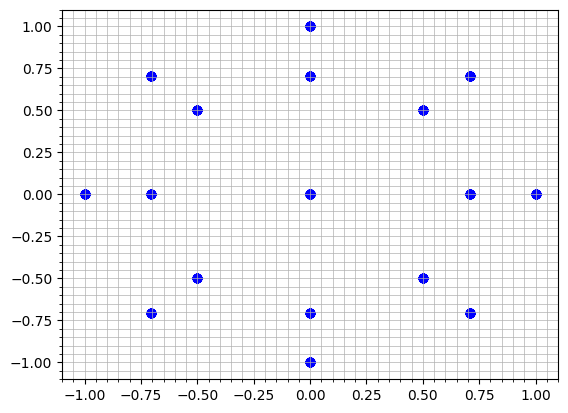

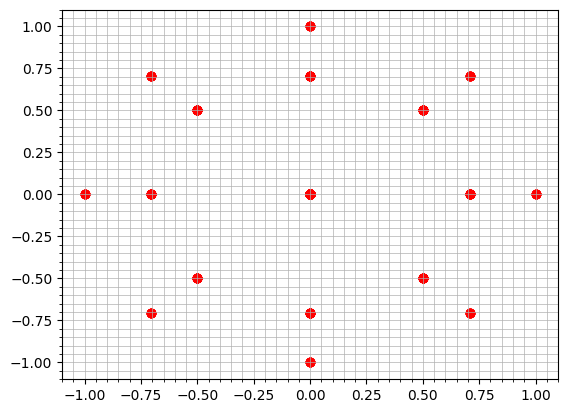

X1 = (288,)
X2 = (288,)
X3 = (288,)
X4 = (288,)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

X1 = []
X2 = []
X3 = []
X4 = []

phi_vals = [0, np.pi, np.pi/2, np.pi/2, np.pi/2, np.pi/2]
theta_vals = [0, 0, 0, np.pi/2, np.pi, 3*np.pi/2]
varphi_vals = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi, 5*np.pi/4, 3*np.pi/2, 7*np.pi/4]

for theta in theta_vals:
    for phi in phi_vals:
        for varphi in varphi_vals:
            X1.append(np.cos(theta/2) * np.cos(varphi + phi/2))
            X2.append(np.cos(theta/2) * np.sin(varphi + phi/2))
            X3.append(np.sin(theta/2) * np.cos(varphi - phi/2))
            X4.append(np.sin(theta/2) * np.sin(varphi - phi/2))

plt.figure(20)
plt.scatter(X1, X2, color='b')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()

plt.figure(21)
plt.scatter(X3, X4, color='r')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()

plt.show()

print('X1 =', np.shape(X1))
print('X2 =', np.shape(X2))
print('X3 =', np.shape(X3))
print('X4 =', np.shape(X4))



# QAM 8 pontos

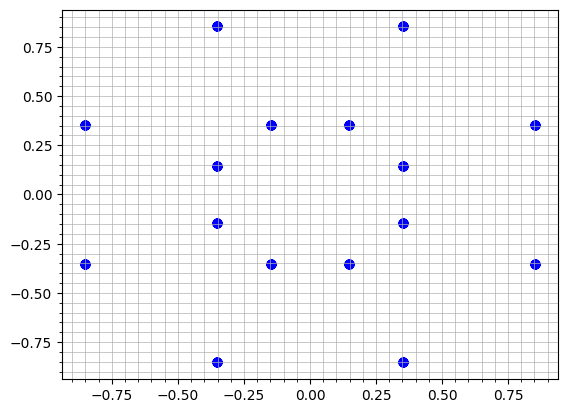

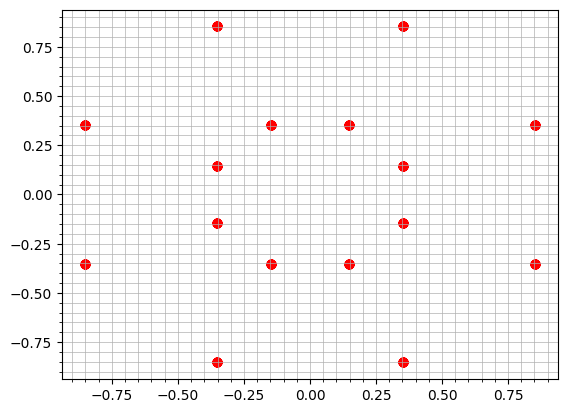

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

X1 = []
X2 = []
X3 = []
X4 = []

phi_vals = [np.pi / 4, np.pi / 4, np.pi / 4, np.pi / 4, 3 * np.pi / 4, 3 * np.pi / 4, 3 * np.pi / 4, 3 * np.pi / 4]
theta_vals = [np.pi / 4,3 * np.pi / 4,5 * np.pi / 4,7 * np.pi / 4,np.pi / 4,3 * np.pi / 4,5 * np.pi / 4 ,7 * np.pi / 4]
varphi_vals = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi, 5*np.pi/4, 3*np.pi/2, 7*np.pi/4]

for theta in theta_vals:
    for phi in phi_vals:
        for varphi in varphi_vals:
            X1.append(np.cos(theta/2) * np.cos(varphi + phi/2))
            X2.append(np.cos(theta/2) * np.sin(varphi + phi/2))
            X3.append(np.sin(theta/2) * np.cos(varphi - phi/2))
            X4.append(np.sin(theta/2) * np.sin(varphi - phi/2))

plt.figure(20)
plt.scatter(X1, X2, color='b')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()

plt.figure(21)
plt.scatter(X3, X4, color='r')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()

plt.show()

# QAM 16 pontos




Foram ralizadas 128 operações




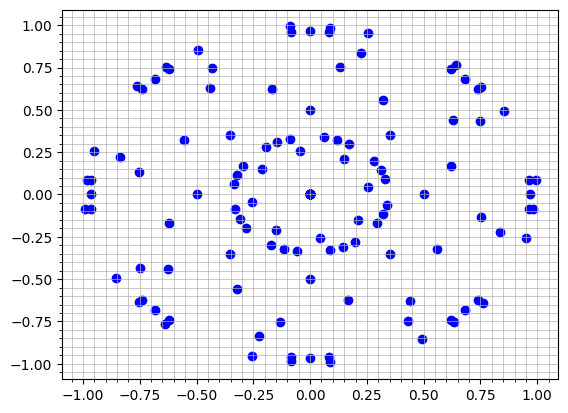

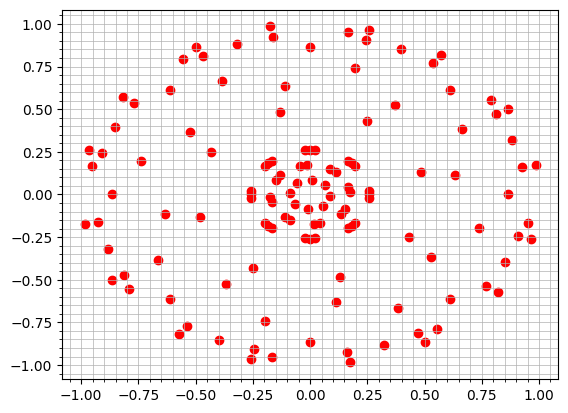

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

X1 = []
X2 = []
X3 = []
X4 = []

theta_vals = [np.pi/3, -13*np.pi/6, np.pi/18, np.pi, -7*np.pi/9, -7*np.pi/9, 4*np.pi/3, np.pi, -np.pi/9, np.pi/9, -4*np.pi/9, -13*np.pi/6, 7*np.pi/6, -np.pi/6, 11*np.pi/9, 13*np.pi/9]
phi_vals = [-np.pi/6, -5*np.pi/9, 5*np.pi/9, np.pi/6, np.pi/6, 7*np.pi/18, 0, -np.pi/9, -2*np.pi/3, -np.pi/18, -np.pi/9, np.pi/18, np.pi/9, 0, 5*np.pi/18, -np.pi/3]
varphi_vals = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi, 5*np.pi/4, 3*np.pi/2, 7*np.pi/4]

# for theta in theta_vals:
#     for phi in phi_vals:
#         for varphi in varphi_vals:
#             X1.append(np.cos(theta/2) * np.cos(varphi + phi/2))
#             X2.append(np.cos(theta/2) * np.sin(varphi + phi/2))
#             X3.append(np.sin(theta/2) * np.cos(varphi - phi/2))
#             X4.append(np.sin(theta/2) * np.sin(varphi - phi/2))

count = 0
for n in range(len(theta_vals)):
    theta = theta_vals[n]
    phi = phi_vals[n]
    for varphi in varphi_vals:
        count += 1
        X1.append(np.cos(theta/2) * np.cos(varphi + phi/2))
        X2.append(np.cos(theta/2) * np.sin(varphi + phi/2))
        X3.append(np.sin(theta/2) * np.cos(varphi - phi/2))
        X4.append(np.sin(theta/2) * np.sin(varphi - phi/2))

print(f'\n\nForam ralizadas {count} operações\n\n')

plt.figure(20)
plt.scatter(X1, X2, color='b')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()

plt.figure(21)
plt.scatter(X3, X4, color='r')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()

plt.show()


In [ ]:
print('X1 =', np.shape(X1))
print('X2 =', np.shape(X2))
print('X3 =', np.shape(X3))
print('X4 =', np.shape(X4))

X1 = (128,)
X2 = (128,)
X3 = (128,)
X4 = (128,)


# 8 Pontos Ótimos com ruidos

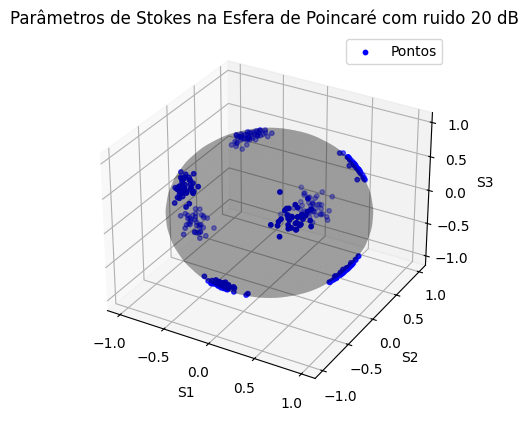

[ 8.14161746e-01 -2.92417421e-02  4.93428642e-03  5.66210340e-01
  6.50603287e-01  9.18703888e-01 -6.52965093e-01 -2.86461067e-01
 -4.47539720e-01  4.00322169e-01 -5.22777926e-01 -6.05696586e-01
 -2.14976661e-02 -5.99424145e-01 -5.38643364e-01  2.24991394e-01
 -5.07051320e-01  5.75388366e-01 -6.51873561e-01 -6.76549189e-02
 -6.33673254e-01  5.82910037e-01 -6.15979585e-01  8.28222873e-01
  1.93932370e-01 -8.97566578e-01 -6.45151269e-01 -8.13986554e-01
  8.97376255e-01  2.97877300e-02  4.55070544e-01  3.21963328e-02
 -5.08133146e-01  5.60097505e-01  6.78410233e-01  4.81807874e-01
 -1.09100403e-02  5.16136070e-01 -4.37606669e-03 -5.40231743e-01
 -7.51150108e-01  6.38959612e-01  7.06872843e-02 -4.44076482e-01
  7.01701318e-01 -6.70177334e-01  4.06340059e-02  7.95151212e-01
  5.81681451e-01 -4.48574691e-02  8.10907666e-01  1.87594537e-01
  5.42068883e-01 -5.74184987e-01 -1.97662648e-01 -8.30283394e-01
 -8.85697752e-01  6.73592547e-01  6.74000973e-01 -1.69800169e-01
 -5.59569882e-01  2.87565

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros iniciais
m = 8
bits = np.random.randint(0, 2, 1026)
phi = []
E_x = []
E_y = []
S0 = []
S1 = []
S2 = []
S3 = []
colorlist = np.random.rand(16, 3)

# Mapeamento de bits para valores E_x, E_y e phi
for i in range(0, len(bits), 3):
    bits_entrada = bits[i:i+3]
    if np.array_equal(bits_entrada, [0, 0, 0]):
        E_x.append(0.8966)
        phi0 = 40.06 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4428 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 0, 1]):
        E_x.append(0.4428)
        phi0 = 40.06 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8966 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 1, 0]):
        E_x.append(0.8966)
        phi0 = 139.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4428 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 1, 1]):
        E_x.append(0.4428)
        phi0 = 139.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8966 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 0, 0]):
        E_x.append(0.9642)
        phi0 = -90 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.2649 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 0, 1]):
        E_x.append(0.2649)
        phi0 = -90 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.9642 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 1, 0]):
        E_x.append(0.7071)
        phi0 = -30.73 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.7071 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 1, 1]):
        E_x.append(0.7071)
        phi0 = -149.27 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.7071 * np.exp(1j * phi0))

# Adição de ruído
SNR = 20  # dB
SNR_Lin = 10**(SNR / 10)
Pn = 1 / SNR_Lin
Pnx = Pn / 2
Pny = Pn / 2

E_x = np.array(E_x) + np.sqrt(Pnx / 2) * (np.random.randn(len(E_x)) + 1j * np.random.randn(len(E_x)))
E_y = np.array(E_y) + np.sqrt(Pny / 2) * (np.random.randn(len(E_y)) + 1j * np.random.randn(len(E_y)))

# Cálculo dos parâmetros de Stokes
for i in range(len(E_x)):
    S0.append(abs(E_x[i])**2 + abs(E_y[i])**2)
    S1.append(abs(E_x[i])**2 - abs(E_y[i])**2)
    S2.append(2 * np.real(E_x[i] * np.conj(E_y[i])))
    S3.append(-2 * np.imag(E_x[i] * np.conj(E_y[i])))

S0 = np.array(S0)
S1 = np.array(S1)
S2 = np.array(S2)
S3 = np.array(S3)

# Normalização dos parâmetros de Stokes
S0n = S0 / S0
S1n = S1 / S0
S2n = S2 / S0
S3n = S3 / S0

# Esfera de Poincaré
t = np.linspace(-np.pi, np.pi, 40)
s = np.linspace(-np.pi, np.pi, 40)
x = np.outer(np.cos(t), np.sin(s))
y = np.outer(np.sin(t), np.sin(s))
z = np.outer(np.ones(len(t)), np.cos(s))

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x, y, z, color='k', alpha=0.1)
ax.scatter(S1n, S2n, S3n, color='b', label='Pontos', s=10)
ax.grid(True)
ax.set_xlabel('S1')
ax.set_ylabel('S2')
ax.set_zlabel('S3')
plt.title('Parâmetros de Stokes na Esfera de Poincaré com ruido 20 dB')
plt.legend()
plt.show()

# print( S1n, S2n, S3n)


# Adição de Ruido na Transmissão



Foram realizadas 64 operações




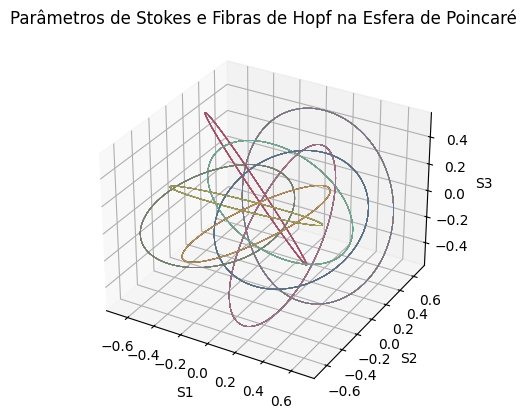

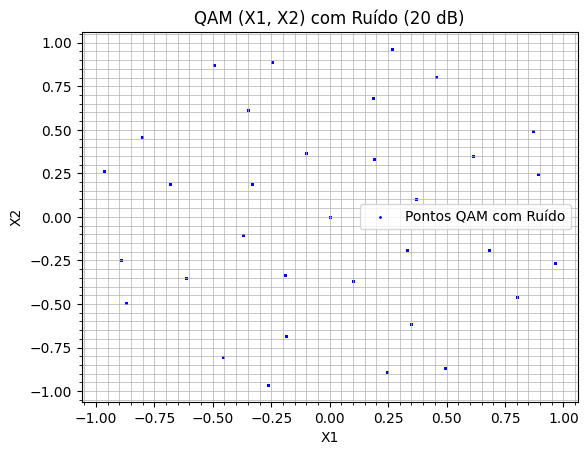

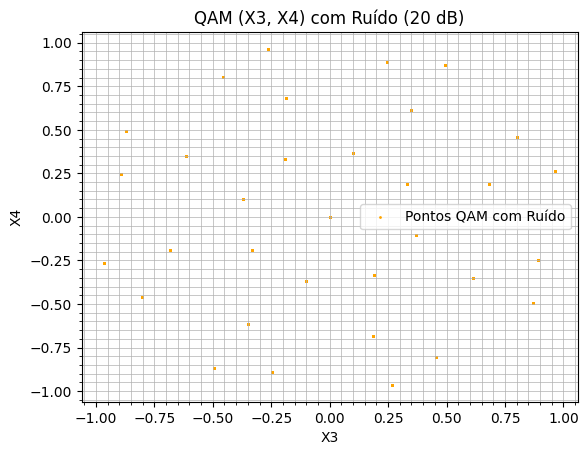

Foram aplicadas 342 iterações de ruído nos pontos QAM.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from matplotlib import colormaps

# Função para mapear a fibriação de Hopf
def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

# Gerando os pontos ótimos com ruído
m = 8
bits = np.random.randint(0, 2, 1026)
phi = []
E_x = []
E_y = []
S0 = []
S1 = []
S2 = []
S3 = []

# Mapeamento de bits para valores E_x, E_y e phi
for i in range(0, len(bits), 3):
    bits_entrada = bits[i:i+3]
    if np.array_equal(bits_entrada, [0, 0, 0]):
        E_x.append(0.8966)
        phi0 = 40.06 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4428 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 0, 1]):
        E_x.append(0.4428)
        phi0 = 40.06 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8966 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 1, 0]):
        E_x.append(0.8966)
        phi0 = 139.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4428 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 1, 1]):
        E_x.append(0.4428)
        phi0 = 139.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8966 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 0, 0]):
        E_x.append(0.9642)
        phi0 = -90 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.2649 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 0, 1]):
        E_x.append(0.2649)
        phi0 = -90 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.9642 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 1, 0]):
        E_x.append(0.7071)
        phi0 = -30.73 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.7071 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 1, 1]):
        E_x.append(0.7071)
        phi0 = -149.27 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.7071 * np.exp(1j * phi0))

# Adição de ruído
SNR = 200  # dB
SNR_Lin = 10**(SNR / 10)
Pn = 1 / SNR_Lin
Pnx = Pn / 2
Pny = Pn / 2

E_x = np.array(E_x) + np.sqrt(Pnx / 2) * (np.random.randn(len(E_x)) + 1j * np.random.randn(len(E_x)))
E_y = np.array(E_y) + np.sqrt(Pny / 2) * (np.random.randn(len(E_y)) + 1j * np.random.randn(len(E_y)))

# Cálculo dos parâmetros de Stokes
for i in range(len(E_x)):
    S0.append(abs(E_x[i])**2 + abs(E_y[i])**2)
    S1.append(abs(E_x[i])**2 - abs(E_y[i])**2)
    S2.append(2 * np.real(E_x[i] * np.conj(E_y[i])))
    S3.append(-2 * np.imag(E_x[i] * np.conj(E_y[i])))

S0 = np.array(S0)
S1 = np.array(S1)
S2 = np.array(S2)
S3 = np.array(S3)

# Normalização dos parâmetros de Stokes
S0n = S0 / S0
S1n = S1 / S0
S2n = S2 / S0
S3n = S3 / S0

# QAM Points
X1 = []
X2 = []
X3 = []
X4 = []

varphi_vals = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi, 5*np.pi/4, 3*np.pi/2, 7*np.pi/4]

# Definindo os valores de theta e phi
theta_vals = [0.7853, 2.3561, -0.7853, -2.3561, 0.0, 3.1415, 1.5707, -1.5707]
phi_vals = [0.5364, 0.5364, 0.5364, 0.5364, -0.5364, -0.5364, -0.5364, -0.5364]


count = 0
for n in range(len(theta_vals)):
    theta = theta_vals[n]
    phi = phi_vals[n]
    for varphi in varphi_vals:
        count += 1
        X1.append(np.round(np.cos(theta / 2) * np.cos(varphi + phi / 2), 4))
        X2.append(np.round(np.cos(theta / 2) * np.sin(varphi + phi / 2), 4))
        X3.append(np.round(np.sin(theta / 2) * np.cos(varphi - phi / 2), 4))
        X4.append(np.round(np.sin(theta / 2) * np.sin(varphi - phi / 2), 4))

print(f'\n\nForam realizadas {count} operações\n\n')

#esse pedaço ignora os pontos (0,0)
# count = 0
# for n in range(len(theta_vals)):
#     theta = theta_vals[n]
#     phi = phi_vals[n]
#     for varphi in varphi_vals:
#         count += 1
#         x1 = np.round(np.cos(theta / 2) * np.cos(varphi + phi / 2), 4)
#         x2 = np.round(np.cos(theta / 2) * np.sin(varphi + phi / 2), 4)
#         x3 = np.round(np.sin(theta / 2) * np.cos(varphi - phi / 2), 4)
#         x4 = np.round(np.sin(theta / 2) * np.sin(varphi - phi / 2), 4)

#         # Apenas adiciona se não for (0, 0)
#         if not (x1 == 0 and x2 == 0):
#             X1.append(x1)
#             X2.append(x2)
#         if not (x3 == 0 and x4 == 0):
#             X3.append(x3)
#             X4.append(x4)

# print(f'\n\nForam realizadas {count} operações\n')
# print(f'{len(X1)} pontos válidos em (X1, X2)')
# print(f'{len(X3)} pontos válidos em (X3, X4)\n')

# Visualização na Esfera de Poincaré
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Adicionando as fibras de Hopf
for i in range(len(S1n)):
    fx, fy, fz = hopfmap(S1n[i], S2n[i], S3n[i])
    ax.plot3D(fx, fy, fz, linewidth=0.5)

ax.set_xlabel('S1')
ax.set_ylabel('S2')
ax.set_zlabel('S3')
plt.title('Parâmetros de Stokes e Fibras de Hopf na Esfera de Poincaré')
plt.show()

# Configuração do SNR para os pontos QAM

SNR_QAM_Lin = 10**(SNR / 10)
Pn_QAM = 1 / SNR_QAM_Lin
sigma_QAM = np.sqrt(Pn_QAM / 2)  # Desvio padrão do ruído QAM

# Variáveis para os pontos QAM com ruído (em várias instâncias)
X1_noisy = []
X2_noisy = []
X3_noisy = []
X4_noisy = []

# Aplicar ruído iterativamente o mesmo número de vezes que na modulação 8PolSK
num_iteracoes = len(S1n)  # Número de fibras de Hopf geradas

for _ in range(num_iteracoes):
    # Adicionando ruído aos pontos QAM
    X1_noisy.append(np.array(X1) + sigma_QAM * (np.random.randn(len(X1)) + 1j * np.random.randn(len(X1))))
    X2_noisy.append(np.array(X2) + sigma_QAM * (np.random.randn(len(X2)) + 1j * np.random.randn(len(X2))))
    X3_noisy.append(np.array(X3) + sigma_QAM * (np.random.randn(len(X3)) + 1j * np.random.randn(len(X3))))
    X4_noisy.append(np.array(X4) + sigma_QAM * (np.random.randn(len(X4)) + 1j * np.random.randn(len(X4))))

# Combinar os resultados de todas as iterações para visualização conjunta
X1_noisy_combined = np.hstack(X1_noisy).real
X2_noisy_combined = np.hstack(X2_noisy).real
X3_noisy_combined = np.hstack(X3_noisy).real
X4_noisy_combined = np.hstack(X4_noisy).real

# Visualização dos pontos QAM dispersos pelo ruído
plt.figure(1)
plt.scatter(X1_noisy_combined, X2_noisy_combined, color='b', s=1, label='Pontos QAM com Ruído')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()
plt.title('QAM (X1, X2) com Ruído (20 dB)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()

plt.figure(2)
plt.scatter(X3_noisy_combined, X4_noisy_combined, color='orange', s=1, label='Pontos QAM com Ruído')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()
plt.title('QAM (X3, X4) com Ruído (20 dB)')
plt.xlabel('X3')
plt.ylabel('X4')
plt.legend()

plt.show()

# Exibindo a quantidade de iterações realizadas
print(f"Foram aplicadas {num_iteracoes} iterações de ruído nos pontos QAM.")


# K-means 8 pontos com ruido

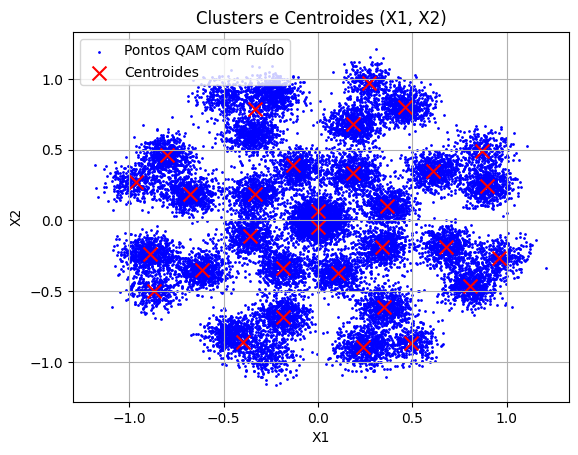

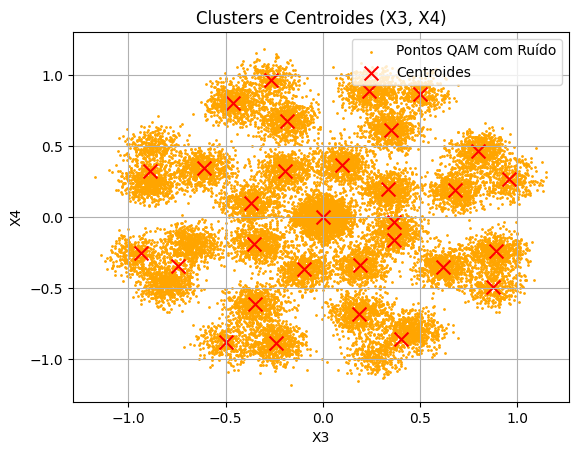

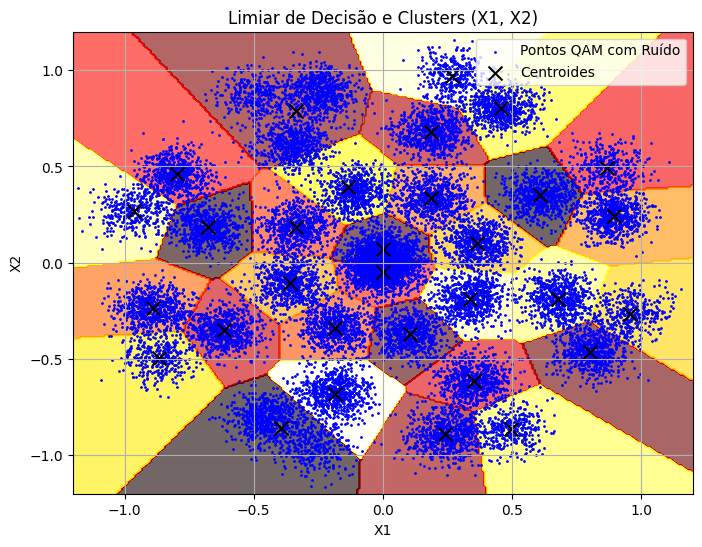

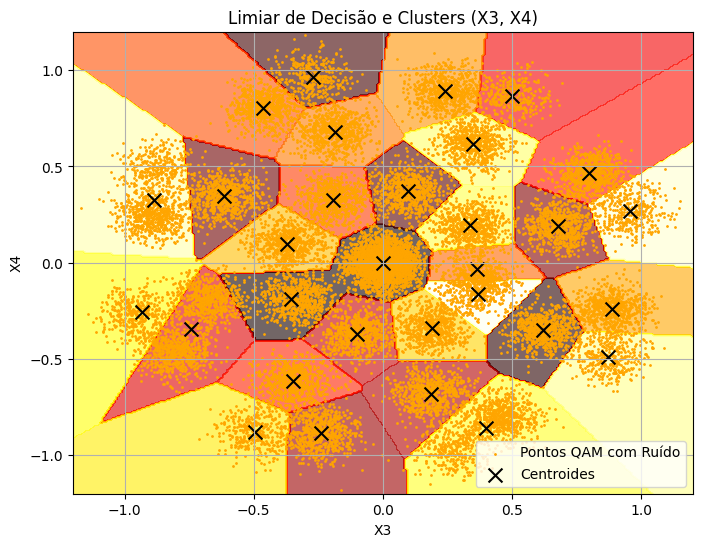

In [ ]:

true_labels_qam1 = np.zeros(len(X1_noisy_combined))
true_labels_qam2 = np.zeros(len(X3_noisy_combined))
# Dados combinados para clustering
data_qam1 = np.vstack((X1_noisy_combined, X2_noisy_combined)).T  # (X1, X2)
data_qam2 = np.vstack((X3_noisy_combined, X4_noisy_combined)).T  # (X3, X4)

# Número de clusters (igual ao número de pontos na constelação QAM original)
n_clusters = 31

# Aplicando k-means nos dados (X1, X2)
kmeans_qam1 = KMeans(n_clusters=n_clusters, random_state=42).fit(data_qam1)
labels_qam1 = kmeans_qam1.labels_
centroids_qam1 = kmeans_qam1.cluster_centers_

# Aplicando k-means nos dados (X3, X4)
kmeans_qam2 = KMeans(n_clusters=n_clusters, random_state=42).fit(data_qam2)
labels_qam2 = kmeans_qam2.labels_
centroids_qam2 = kmeans_qam2.cluster_centers_

# Visualização dos clusters e centroides para (X1, X2)
plt.figure(1)
plt.scatter(data_qam1[:, 0], data_qam1[:, 1], color='b', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam1[:, 0], centroids_qam1[:, 1], c='red', marker='x', s=100, label='Centroides')
plt.title('Clusters e Centroides (X1, X2)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.grid(True)
plt.legend()

# Visualização dos clusters e centroides para (X3, X4)
plt.figure(2)
plt.scatter(data_qam2[:, 0], data_qam2[:, 1], color='orange', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam2[:, 0], centroids_qam2[:, 1], c='red', marker='x', s=100, label='Centroides')
plt.title('Clusters e Centroides (X3, X4)')
plt.xlabel('X3')
plt.ylabel('X4')
plt.grid(True)
plt.legend()

plt.show()



# Função para calcular o limiar de decisão
def decision_boundary(X, Y, centroids):
    # Calcular as distâncias de cada ponto aos centroides
    distances = cdist(np.c_[X.ravel(), Y.ravel()], centroids, 'euclidean')

    # Atribuir o cluster mais próximo para cada ponto na grade
    labels = np.argmin(distances, axis=1).reshape(X.shape)
    return labels

# Criando uma grade para visualizar o limiar de decisão
x_min, x_max = data_qam1[:, 0].min() - 1, data_qam1[:, 0].max() + 1
y_min, y_max = data_qam1[:, 1].min() - 1, data_qam1[:, 1].max() + 1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

# Calcular os limiares de decisão para (X1, X2)
decision_labels_qam1 = decision_boundary(xx, yy, centroids_qam1)

# Visualização do limiar de decisão para (X1, X2)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, decision_labels_qam1,levels=30, alpha=0.6, cmap='hot')
plt.scatter(data_qam1[:, 0], data_qam1[:, 1], color='b', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam1[:, 0], centroids_qam1[:, 1], c='black', marker='x', s=100, label='Centroides')
plt.title('Limiar de Decisão e Clusters (X1, X2)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.grid(True)
plt.legend()

# Calcular os limiares de decisão para (X3, X4)
decision_labels_qam2 = decision_boundary(xx, yy, centroids_qam2)

# Visualização do limiar de decisão para (X3, X4)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, decision_labels_qam2, levels=30,  alpha=0.6, cmap='hot')
plt.scatter(data_qam2[:, 0], data_qam2[:, 1], color='orange', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam2[:, 0], centroids_qam2[:, 1], c='black', marker='x', s=100, label='Centroides')
plt.title('Limiar de Decisão e Clusters (X3, X4)')
plt.xlabel('X3')
plt.ylabel('X4')
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.grid(True)
plt.legend()

plt.show()




In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score,precision_score, recall_score, f1_score
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
import numpy as np


# 1. Rótulos verdadeiros (0 a 30) para cada ponto sem ruído, repetidos por iteração
n_points = len(X1)
true_labels_qam1 = np.tile(np.arange(n_points), num_iteracoes)
true_labels_qam2 = np.tile(np.arange(n_points), num_iteracoes)

# 2. Atribuição do rótulo ideal ao ponto ruidoso mais próximo (como verdade "reconhecida")
def assign_true_labels(noisy_data, clean_constellation):
    distances = cdist(noisy_data, clean_constellation)
    return np.argmin(distances, axis=1)

qam1_clean = np.vstack((X1, X2)).T
qam2_clean = np.vstack((X3, X4)).T

matched_labels_qam1 = assign_true_labels(data_qam1, qam1_clean)
matched_labels_qam2 = assign_true_labels(data_qam2, qam2_clean)

# 3. Remapeamento dos rótulos do KMeans com Hungarian Algorithm (scipy)
def remap_labels(true_labels, pred_labels):
    D = max(true_labels.max(), pred_labels.max()) + 1
    cost_matrix = np.zeros((D, D), dtype=np.int64)
    for i in range(len(true_labels)):
        cost_matrix[true_labels[i], pred_labels[i]] += 1
    row_ind, col_ind = linear_sum_assignment(-cost_matrix)  # Maximiza os acertos
    mapping = {col: row for row, col in zip(row_ind, col_ind)}
    new_preds = np.array([mapping.get(label, label) for label in pred_labels])
    return new_preds

# Aplicar remapeamento
labels_qam1_mapped = remap_labels(matched_labels_qam1, labels_qam1)
labels_qam2_mapped = remap_labels(matched_labels_qam2, labels_qam2)

# 4. Métricas para QAM1
print("=== Métricas para QAM (X1, X2) ===")
print("Acurácia:", accuracy_score(matched_labels_qam1, labels_qam1_mapped))
print("Precisão (macro):", precision_score(matched_labels_qam1, labels_qam1_mapped, average='macro', zero_division=0))
print("Precisão (micro):", precision_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))
print("Recall", recall_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))
print("F1 Score", f1_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))

# 5. Métricas para QAM2
print("=== Métricas para QAM (X3, X4) ===")
print("Acurácia:", accuracy_score(matched_labels_qam2, labels_qam2_mapped))
print("Precisão (macro):", precision_score(matched_labels_qam2, labels_qam2_mapped, average='macro', zero_division=0))
print("Precisão (micro):", precision_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))
print("Recall", recall_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))
print("F1 Score", f1_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))




=== Métricas para QAM (X1, X2) ===
Acurácia: 0.8279879385964912
Precisão (macro): 0.7824182828356103
Precisão (micro): 0.8279879385964912
Recall 0.8279879385964912
F1 Score 0.8279879385964912
=== Métricas para QAM (X3, X4) ===
Acurácia: 0.8498720760233918
Precisão (macro): 0.7792664792824855
Precisão (micro): 0.8498720760233918
Recall 0.8498720760233918
F1 Score 0.8498720760233918


# EM 8 pontos com ruido



Foram realizadas 64 operações




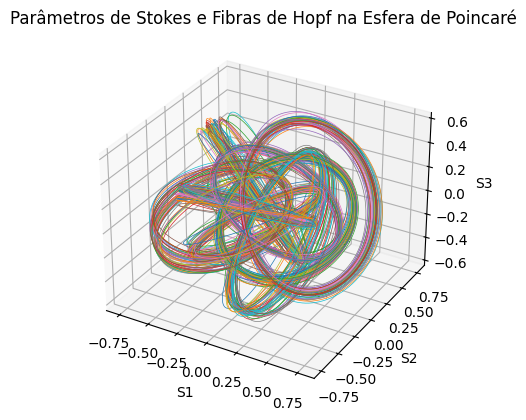

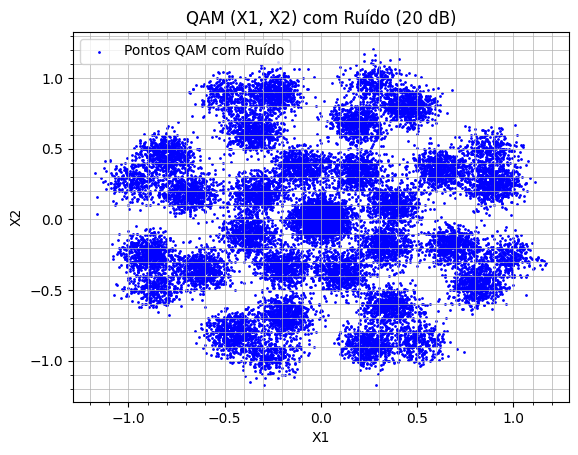

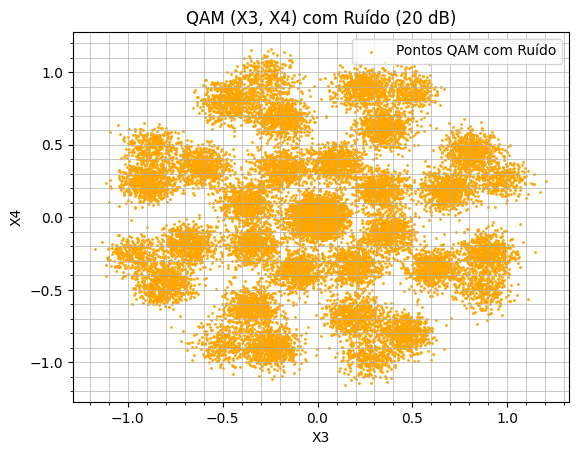

Foram aplicadas 342 iterações de ruído nos pontos QAM.


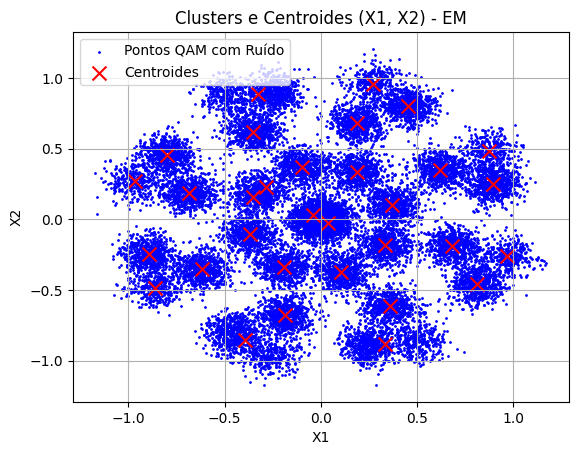

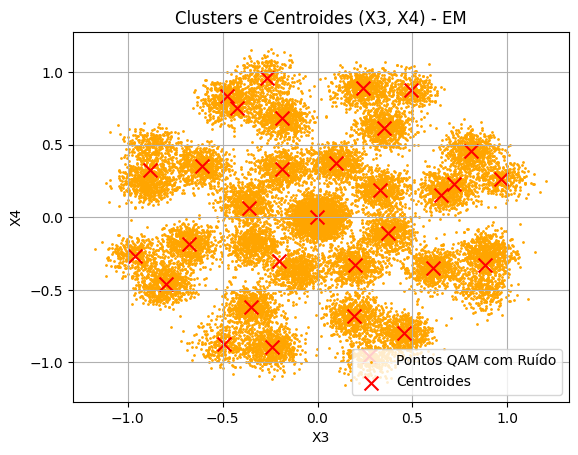

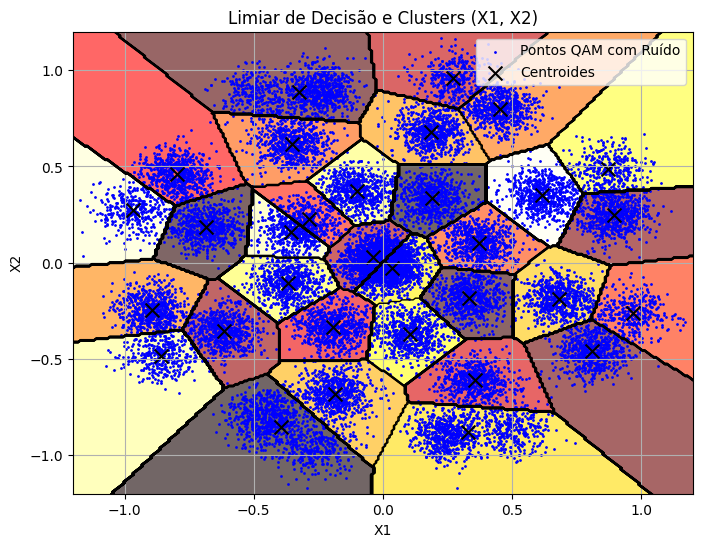

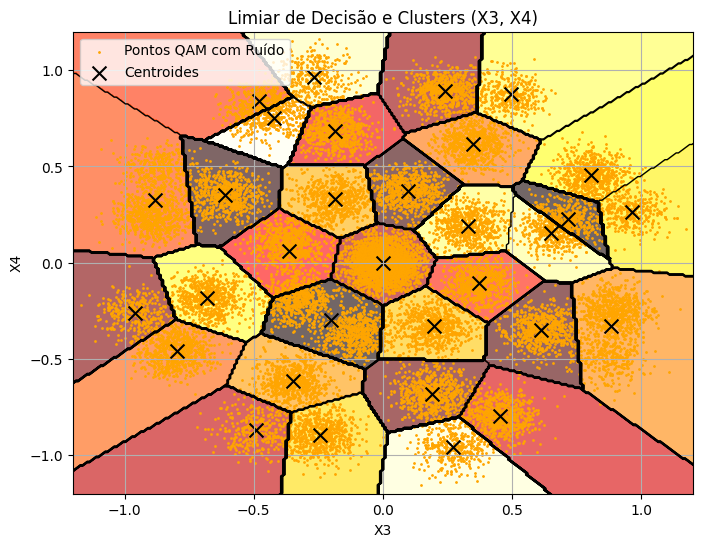

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from sklearn.mixture import GaussianMixture
from matplotlib import colormaps

# Função para mapear a fibriação de Hopf
def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

# Gerando os pontos ótimos com ruído
m = 8
bits = np.random.randint(0, 2, 1026)
phi = []
E_x = []
E_y = []
S0 = []
S1 = []
S2 = []
S3 = []

# Mapeamento de bits para valores E_x, E_y e phi
for i in range(0, len(bits), 3):
    bits_entrada = bits[i:i+3]
    if np.array_equal(bits_entrada, [0, 0, 0]):
        E_x.append(0.8966)
        phi0 = 40.06 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4428 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 0, 1]):
        E_x.append(0.4428)
        phi0 = 40.06 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8966 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 1, 0]):
        E_x.append(0.8966)
        phi0 = 139.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4428 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 1, 1]):
        E_x.append(0.4428)
        phi0 = 139.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8966 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 0, 0]):
        E_x.append(0.9642)
        phi0 = -90 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.2649 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 0, 1]):
        E_x.append(0.2649)
        phi0 = -90 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.9642 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 1, 0]):
        E_x.append(0.7071)
        phi0 = -30.73 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.7071 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 1, 1]):
        E_x.append(0.7071)
        phi0 = -149.27 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.7071 * np.exp(1j * phi0))

# Adição de ruído
SNR = 20  # dB
SNR_Lin = 10**(SNR / 10)
Pn = 1 / SNR_Lin
Pnx = Pn / 2
Pny = Pn / 2

E_x = np.array(E_x) + np.sqrt(Pnx / 2) * (np.random.randn(len(E_x)) + 1j * np.random.randn(len(E_x)))
E_y = np.array(E_y) + np.sqrt(Pny / 2) * (np.random.randn(len(E_y)) + 1j * np.random.randn(len(E_y)))

# Cálculo dos parâmetros de Stokes
for i in range(len(E_x)):
    S0.append(abs(E_x[i])**2 + abs(E_y[i])**2)
    S1.append(abs(E_x[i])**2 - abs(E_y[i])**2)
    S2.append(2 * np.real(E_x[i] * np.conj(E_y[i])))
    S3.append(-2 * np.imag(E_x[i] * np.conj(E_y[i])))

S0 = np.array(S0)
S1 = np.array(S1)
S2 = np.array(S2)
S3 = np.array(S3)

# Normalização dos parâmetros de Stokes
S0n = S0 / S0
S1n = S1 / S0
S2n = S2 / S0
S3n = S3 / S0

# QAM Points
X1 = []
X2 = []
X3 = []
X4 = []

varphi_vals = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi, 5*np.pi/4, 3*np.pi/2, 7*np.pi/4]

# Definindo os valores de theta e phi
theta_vals = [0.7853, 2.3561, -0.7853, -2.3561, 0.0, 3.1415, 1.5707, -1.5707]
phi_vals = [0.5364, 0.5364, 0.5364, 0.5364, -0.5364, -0.5364, -0.5364, -0.5364]

count = 0
for n in range(len(theta_vals)):
    theta = theta_vals[n]
    phi = phi_vals[n]
    for varphi in varphi_vals:
        count += 1
        X1.append(np.round(np.cos(theta / 2) * np.cos(varphi + phi / 2), 4))
        X2.append(np.round(np.cos(theta / 2) * np.sin(varphi + phi / 2), 4))
        X3.append(np.round(np.sin(theta / 2) * np.cos(varphi - phi / 2), 4))
        X4.append(np.round(np.sin(theta / 2) * np.sin(varphi - phi / 2), 4))

print(f'\n\nForam realizadas {count} operações\n\n')

# Visualização na Esfera de Poincaré
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Adicionando as fibras de Hopf
for i in range(len(S1n)):
    fx, fy, fz = hopfmap(S1n[i], S2n[i], S3n[i])
    ax.plot3D(fx, fy, fz, linewidth=0.5)

ax.set_xlabel('S1')
ax.set_ylabel('S2')
ax.set_zlabel('S3')
plt.title('Parâmetros de Stokes e Fibras de Hopf na Esfera de Poincaré')
plt.show()

# Configuração do SNR para os pontos QAM
SNR_QAM = 20 # dB
SNR_QAM_Lin = 10**(SNR_QAM / 10)
Pn_QAM = 1 / SNR_QAM_Lin
sigma_QAM = np.sqrt(Pn_QAM / 2)  # Desvio padrão do ruído QAM

# Variáveis para os pontos QAM com ruído (em várias instâncias)
X1_noisy = []
X2_noisy = []
X3_noisy = []
X4_noisy = []

# Aplicar ruído iterativamente o mesmo número de vezes que na modulação 8PolSK
num_iteracoes = len(S1n)  # Número de fibras de Hopf geradas

for _ in range(num_iteracoes):
    # Adicionando ruído aos pontos QAM
    X1_noisy.append(np.array(X1) + sigma_QAM * (np.random.randn(len(X1)) + 1j * np.random.randn(len(X1))))
    X2_noisy.append(np.array(X2) + sigma_QAM * (np.random.randn(len(X2)) + 1j * np.random.randn(len(X2))))
    X3_noisy.append(np.array(X3) + sigma_QAM * (np.random.randn(len(X3)) + 1j * np.random.randn(len(X3))))
    X4_noisy.append(np.array(X4) + sigma_QAM * (np.random.randn(len(X4)) + 1j * np.random.randn(len(X4))))

# Combinar os resultados de todas as iterações para visualização conjunta
X1_noisy_combined = np.hstack(X1_noisy).real
X2_noisy_combined = np.hstack(X2_noisy).real
X3_noisy_combined = np.hstack(X3_noisy).real
X4_noisy_combined = np.hstack(X4_noisy).real

# Visualização dos pontos QAM dispersos pelo ruído
plt.figure(1)
plt.scatter(X1_noisy_combined, X2_noisy_combined, color='b', s=1, label='Pontos QAM com Ruído')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()
plt.title('QAM (X1, X2) com Ruído (20 dB)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()

plt.figure(2)
plt.scatter(X3_noisy_combined, X4_noisy_combined, color='orange', s=1, label='Pontos QAM com Ruído')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()
plt.title('QAM (X3, X4) com Ruído (20 dB)')
plt.xlabel('X3')
plt.ylabel('X4')
plt.legend()

plt.show()

# Exibindo a quantidade de iterações realizadas
print(f"Foram aplicadas {num_iteracoes} iterações de ruído nos pontos QAM.")


# Dados combinados para clustering
data_qam1 = np.vstack((X1_noisy_combined, X2_noisy_combined)).T  # (X1, X2)
data_qam2 = np.vstack((X3_noisy_combined, X4_noisy_combined)).T  # (X3, X4)

# Número de clusters (igual ao número de pontos na constelação QAM original)
n_clusters = 32

# Aplicando EM (GMM) nos dados (X1, X2)
gmm_qam1 = GaussianMixture(n_components=n_clusters, random_state=42).fit(data_qam1)
labels_qam1 = gmm_qam1.predict(data_qam1)
centroids_qam1 = gmm_qam1.means_

# Aplicando EM (GMM) nos dados (X3, X4)
gmm_qam2 = GaussianMixture(n_components=n_clusters, random_state=42).fit(data_qam2)
labels_qam2 = gmm_qam2.predict(data_qam2)
centroids_qam2 = gmm_qam2.means_

# Visualização dos clusters e centroides para (X1, X2)
plt.figure(1)
plt.scatter(data_qam1[:, 0], data_qam1[:, 1], color='b', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam1[:, 0], centroids_qam1[:, 1], c='red', marker='x', s=100, label='Centroides')
plt.title('Clusters e Centroides (X1, X2) - EM')
plt.xlabel('X1')
plt.ylabel('X2')
plt.grid(True)
plt.legend()

# Visualização dos clusters e centroides para (X3, X4)
plt.figure(2)
plt.scatter(data_qam2[:, 0], data_qam2[:, 1], color='orange', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam2[:, 0], centroids_qam2[:, 1], c='red', marker='x', s=100, label='Centroides')
plt.title('Clusters e Centroides (X3, X4) - EM')
plt.xlabel('X3')
plt.ylabel('X4')
plt.grid(True)
plt.legend()

plt.show()

# Função para calcular o limiar de decisão
def decision_boundary(X, Y, centroids):
    distances = cdist(np.c_[X.ravel(), Y.ravel()], centroids, 'euclidean')
    labels = np.argmin(distances, axis=1).reshape(X.shape)
    return labels

# Criando uma grade para visualizar os limiares de decisão
x_min, x_max = data_qam1[:, 0].min() - 1, data_qam1[:, 0].max() + 1
y_min, y_max = data_qam1[:, 1].min() - 1, data_qam1[:, 1].max() + 1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

# Calcular os limiares de decisão para (X1, X2)
decision_labels_qam1 = decision_boundary(xx, yy, centroids_qam1)

# Visualização do limiar de decisão para (X1, X2)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, decision_labels_qam1, levels=30, alpha=0.6, cmap='hot')
plt.contour(xx, yy, decision_labels_qam1, levels=np.arange(len(centroids_qam1) + 1) - 0.5, colors='black', linewidths=1)
plt.scatter(data_qam1[:, 0], data_qam1[:, 1], color='b', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam1[:, 0], centroids_qam1[:, 1], c='black', marker='x', s=100, label='Centroides')
plt.title('Limiar de Decisão e Clusters (X1, X2)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.grid(True)
plt.legend()

# Calcular os limiares de decisão para (X3, X4)
decision_labels_qam2 = decision_boundary(xx, yy, centroids_qam2)

# Visualização do limiar de decisão para (X3, X4)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, decision_labels_qam2, levels=30, alpha=0.6, cmap='hot')
plt.contour(xx, yy, decision_labels_qam2, levels=np.arange(len(centroids_qam2) + 1) - 0.5, colors='black', linewidths=1)
plt.scatter(data_qam2[:, 0], data_qam2[:, 1], color='orange', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam2[:, 0], centroids_qam2[:, 1], c='black', marker='x', s=100, label='Centroides')
plt.title('Limiar de Decisão e Clusters (X3, X4)')
plt.xlabel('X3')
plt.ylabel('X4')
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.grid(True)
plt.legend()

plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score,precision_score, recall_score, f1_score
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
import numpy as np


# 1. Rótulos verdadeiros (0 a 30) para cada ponto sem ruído, repetidos por iteração
n_points = len(X1)
true_labels_qam1 = np.tile(np.arange(n_points), num_iteracoes)
true_labels_qam2 = np.tile(np.arange(n_points), num_iteracoes)

# 2. Atribuição do rótulo ideal ao ponto ruidoso mais próximo (como verdade "reconhecida")
def assign_true_labels(noisy_data, clean_constellation):
    distances = cdist(noisy_data, clean_constellation)
    return np.argmin(distances, axis=1)

qam1_clean = np.vstack((X1, X2)).T
qam2_clean = np.vstack((X3, X4)).T

matched_labels_qam1 = assign_true_labels(data_qam1, qam1_clean)
matched_labels_qam2 = assign_true_labels(data_qam2, qam2_clean)

# 3. Remapeamento dos rótulos do KMeans com Hungarian Algorithm (scipy)
def remap_labels(true_labels, pred_labels):
    D = max(true_labels.max(), pred_labels.max()) + 1
    cost_matrix = np.zeros((D, D), dtype=np.int64)
    for i in range(len(true_labels)):
        cost_matrix[true_labels[i], pred_labels[i]] += 1
    row_ind, col_ind = linear_sum_assignment(-cost_matrix)  # Maximiza os acertos
    mapping = {col: row for row, col in zip(row_ind, col_ind)}
    new_preds = np.array([mapping.get(label, label) for label in pred_labels])
    return new_preds

# Aplicar remapeamento
labels_qam1_mapped = remap_labels(matched_labels_qam1, labels_qam1)
labels_qam2_mapped = remap_labels(matched_labels_qam2, labels_qam2)

# 4. Métricas para QAM1
print("=== Métricas para QAM (X1, X2) ===")
print("Acurácia:", accuracy_score(matched_labels_qam1, labels_qam1_mapped))
print("Precisão (macro):", precision_score(matched_labels_qam1, labels_qam1_mapped, average='macro', zero_division=0))
print("Precisão (micro):", precision_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))
print("Recall", recall_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))
print("F1 Score", f1_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))

# 5. Métricas para QAM2
print("=== Métricas para QAM (X3, X4) ===")
print("Acurácia:", accuracy_score(matched_labels_qam2, labels_qam2_mapped))
print("Precisão (macro):", precision_score(matched_labels_qam2, labels_qam2_mapped, average='macro', zero_division=0))
print("Precisão (micro):", precision_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))
print("Recall", recall_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))
print("F1 Score", f1_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))



=== Métricas para QAM (X1, X2) ===
Acurácia: 0.984375
Precisão (macro): 0.9595959595959596
Precisão (micro): 0.984375
Recall 0.984375
F1 Score 0.984375
=== Métricas para QAM (X3, X4) ===
Acurácia: 0.984375
Precisão (macro): 0.9595959595959596
Precisão (micro): 0.984375
Recall 0.984375
F1 Score 0.984375


# DBSCAN 8 Pontos com Ruido



Foram realizadas 64 operações




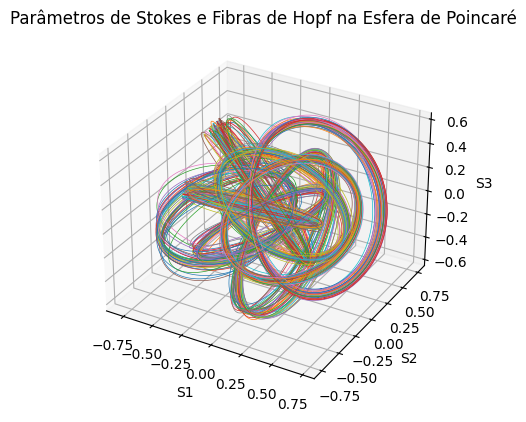

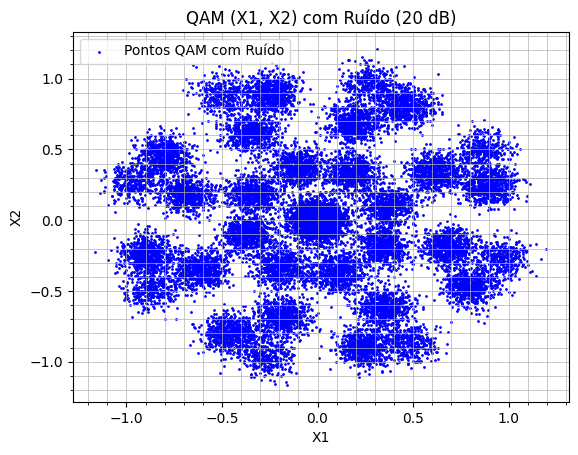

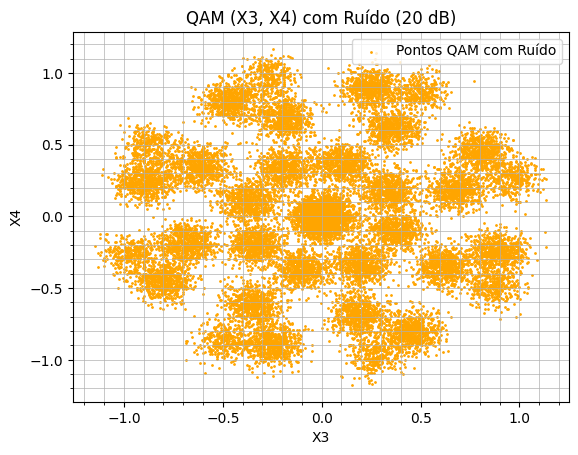

Foram aplicadas 342 iterações de ruído nos pontos QAM.


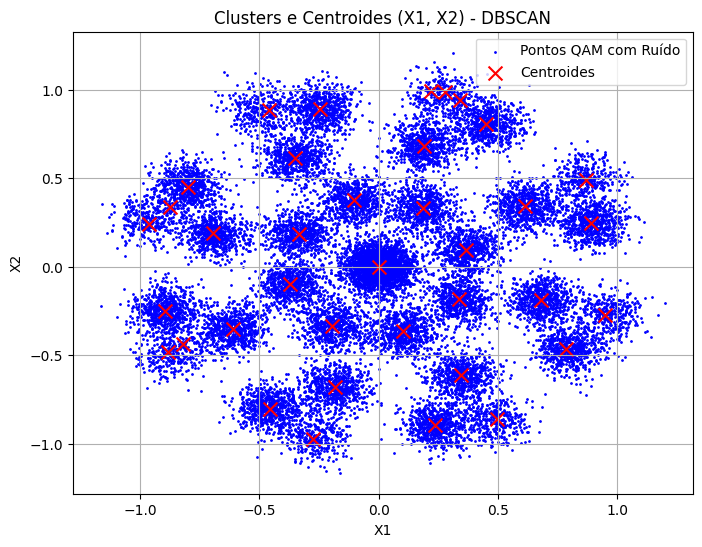

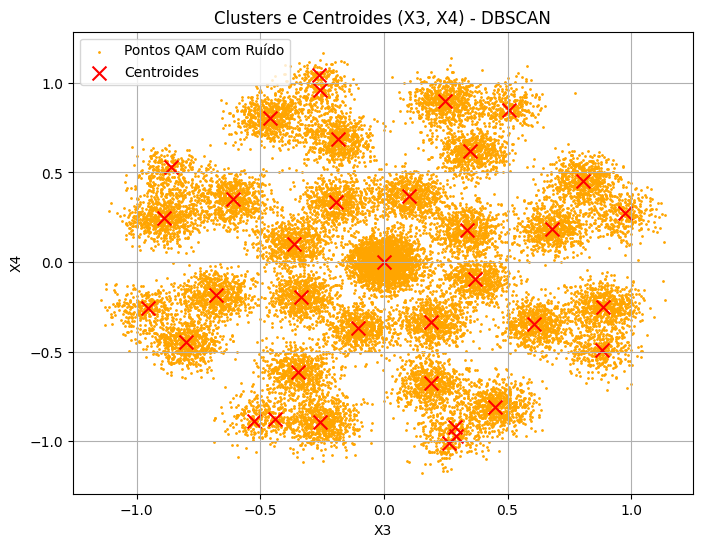

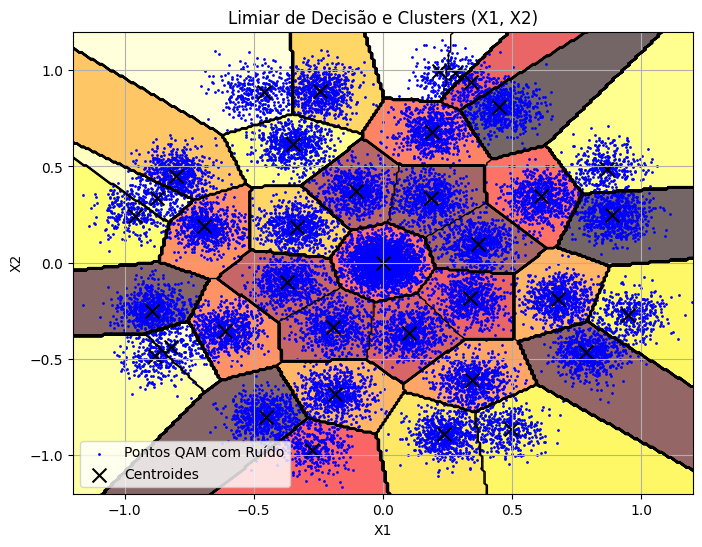

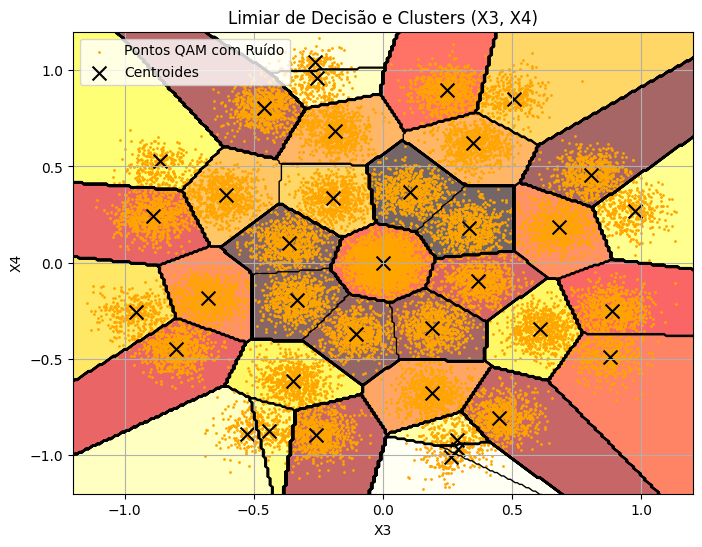

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from matplotlib import colormaps
from sklearn.cluster import DBSCAN

# Função para mapear a fibriação de Hopf
def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

# Gerando os pontos ótimos com ruído
m = 8
bits = np.random.randint(0, 2, 1026)
phi = []
E_x = []
E_y = []
S0 = []
S1 = []
S2 = []
S3 = []

# Mapeamento de bits para valores E_x, E_y e phi
for i in range(0, len(bits), 3):
    bits_entrada = bits[i:i+3]
    if np.array_equal(bits_entrada, [0, 0, 0]):
        E_x.append(0.8966)
        phi0 = 40.06 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4428 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 0, 1]):
        E_x.append(0.4428)
        phi0 = 40.06 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8966 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 1, 0]):
        E_x.append(0.8966)
        phi0 = 139.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4428 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 1, 1]):
        E_x.append(0.4428)
        phi0 = 139.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8966 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 0, 0]):
        E_x.append(0.9642)
        phi0 = -90 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.2649 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 0, 1]):
        E_x.append(0.2649)
        phi0 = -90 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.9642 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 1, 0]):
        E_x.append(0.7071)
        phi0 = -30.73 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.7071 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 1, 1]):
        E_x.append(0.7071)
        phi0 = -149.27 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.7071 * np.exp(1j * phi0))

# Adição de ruído
SNR = 20 # dB
SNR_Lin = 10**(SNR / 10)
Pn = 1 / SNR_Lin
Pnx = Pn / 2
Pny = Pn / 2

E_x = np.array(E_x) + np.sqrt(Pnx / 2) * (np.random.randn(len(E_x)) + 1j * np.random.randn(len(E_x)))
E_y = np.array(E_y) + np.sqrt(Pny / 2) * (np.random.randn(len(E_y)) + 1j * np.random.randn(len(E_y)))

# Cálculo dos parâmetros de Stokes
for i in range(len(E_x)):
    S0.append(abs(E_x[i])**2 + abs(E_y[i])**2)
    S1.append(abs(E_x[i])**2 - abs(E_y[i])**2)
    S2.append(2 * np.real(E_x[i] * np.conj(E_y[i])))
    S3.append(-2 * np.imag(E_x[i] * np.conj(E_y[i])))

S0 = np.array(S0)
S1 = np.array(S1)
S2 = np.array(S2)
S3 = np.array(S3)

# Normalização dos parâmetros de Stokes
S0n = S0 / S0
S1n = S1 / S0
S2n = S2 / S0
S3n = S3 / S0

# QAM Points
X1 = []
X2 = []
X3 = []
X4 = []

varphi_vals = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi, 5*np.pi/4, 3*np.pi/2, 7*np.pi/4]

# Definindo os valores de theta e phi
theta_vals = [0.7853, 2.3561, -0.7853, -2.3561, 0.0, 3.1415, 1.5707, -1.5707]
phi_vals = [0.5364, 0.5364, 0.5364, 0.5364, -0.5364, -0.5364, -0.5364, -0.5364]

count = 0
for n in range(len(theta_vals)):
    theta = theta_vals[n]
    phi = phi_vals[n]
    for varphi in varphi_vals:
        count += 1
        X1.append(np.round(np.cos(theta / 2) * np.cos(varphi + phi / 2), 4))
        X2.append(np.round(np.cos(theta / 2) * np.sin(varphi + phi / 2), 4))
        X3.append(np.round(np.sin(theta / 2) * np.cos(varphi - phi / 2), 4))
        X4.append(np.round(np.sin(theta / 2) * np.sin(varphi - phi / 2), 4))

print(f'\n\nForam realizadas {count} operações\n\n')

# Visualização na Esfera de Poincaré
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Adicionando as fibras de Hopf
for i in range(len(S1n)):
    fx, fy, fz = hopfmap(S1n[i], S2n[i], S3n[i])
    ax.plot3D(fx, fy, fz, linewidth=0.5)

ax.set_xlabel('S1')
ax.set_ylabel('S2')
ax.set_zlabel('S3')
plt.title('Parâmetros de Stokes e Fibras de Hopf na Esfera de Poincaré')
plt.show()

# Configuração do SNR para os pontos QAM
SNR_QAM_Lin = 10**(SNR / 10)
Pn_QAM = 1 / SNR_QAM_Lin
sigma_QAM = np.sqrt(Pn_QAM / 2)  # Desvio padrão do ruído QAM

# Variáveis para os pontos QAM com ruído (em várias instâncias)
X1_noisy = []
X2_noisy = []
X3_noisy = []
X4_noisy = []

# Aplicar ruído iterativamente o mesmo número de vezes que na modulação 8PolSK
num_iteracoes = len(S1n)  # Número de fibras de Hopf geradas

for _ in range(num_iteracoes):
    # Adicionando ruído aos pontos QAM
    X1_noisy.append(np.array(X1) + sigma_QAM * (np.random.randn(len(X1)) + 1j * np.random.randn(len(X1))))
    X2_noisy.append(np.array(X2) + sigma_QAM * (np.random.randn(len(X2)) + 1j * np.random.randn(len(X2))))
    X3_noisy.append(np.array(X3) + sigma_QAM * (np.random.randn(len(X3)) + 1j * np.random.randn(len(X3))))
    X4_noisy.append(np.array(X4) + sigma_QAM * (np.random.randn(len(X4)) + 1j * np.random.randn(len(X4))))

# Combinar os resultados de todas as iterações para visualização conjunta
X1_noisy_combined = np.hstack(X1_noisy).real
X2_noisy_combined = np.hstack(X2_noisy).real
X3_noisy_combined = np.hstack(X3_noisy).real
X4_noisy_combined = np.hstack(X4_noisy).real

# Visualização dos pontos QAM dispersos pelo ruído
plt.figure(1)
plt.scatter(X1_noisy_combined, X2_noisy_combined, color='b', s=1, label='Pontos QAM com Ruído')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()
plt.title('QAM (X1, X2) com Ruído (20 dB)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()

plt.figure(2)
plt.scatter(X3_noisy_combined, X4_noisy_combined, color='orange', s=1, label='Pontos QAM com Ruído')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()
plt.title('QAM (X3, X4) com Ruído (20 dB)')
plt.xlabel('X3')
plt.ylabel('X4')
plt.legend()

plt.show()

# Exibindo a quantidade de iterações realizadas
print(f"Foram aplicadas {num_iteracoes} iterações de ruído nos pontos QAM.")


# Dados combinados para clustering
data_qam1 = np.vstack((X1_noisy_combined, X2_noisy_combined)).T  # (X1, X2)
data_qam2 = np.vstack((X3_noisy_combined, X4_noisy_combined)).T  # (X3, X4)

# Número de clusters (igual ao número de pontos na constelação QAM original)
n_clusters = 32

# Parâmetros do DBSCAN
eps = 0.03  # Distância máxima para considerar um ponto vizinho
min_samples = 30  # Mínimo de pontos para formar um cluster

# Aplicando DBSCAN nos dados (X1, X2)
dbscan_qam1 = DBSCAN(eps=eps, min_samples=min_samples).fit(data_qam1)
labels_qam1 = dbscan_qam1.labels_

# Determinando os centroides dos clusters detectados
unique_labels_qam1 = set(labels_qam1) - {-1}  # Remove rótulo de ruído (-1)
centroids_qam1 = np.array([data_qam1[labels_qam1 == label].mean(axis=0) for label in unique_labels_qam1])

# Aplicando DBSCAN nos dados (X3, X4)
dbscan_qam2 = DBSCAN(eps=eps, min_samples=min_samples).fit(data_qam2)
labels_qam2 = dbscan_qam2.labels_

# Determinando os centroides dos clusters detectados
unique_labels_qam2 = set(labels_qam2) - {-1}  # Remove rótulo de ruído (-1)
centroids_qam2 = np.array([data_qam2[labels_qam2 == label].mean(axis=0) for label in unique_labels_qam2])

# Visualização dos clusters e centroides para (X1, X2)
plt.figure(figsize=(8, 6))
plt.scatter(data_qam1[:, 0], data_qam1[:, 1], color='b', s=1, label='Pontos QAM com Ruído')
if len(centroids_qam1) > 0:
    plt.scatter(centroids_qam1[:, 0], centroids_qam1[:, 1], c='red', marker='x', s=100, label='Centroides')
plt.title('Clusters e Centroides (X1, X2) - DBSCAN')
plt.xlabel('X1')
plt.ylabel('X2')
plt.grid(True)
plt.legend()

# Visualização dos clusters e centroides para (X3, X4)
plt.figure(figsize=(8, 6))
plt.scatter(data_qam2[:, 0], data_qam2[:, 1], color='orange', s=1, label='Pontos QAM com Ruído')
if len(centroids_qam2) > 0:
    plt.scatter(centroids_qam2[:, 0], centroids_qam2[:, 1], c='red', marker='x', s=100, label='Centroides')
plt.title('Clusters e Centroides (X3, X4) - DBSCAN')
plt.xlabel('X3')
plt.ylabel('X4')
plt.grid(True)
plt.legend()

plt.show()
# Função para calcular o limiar de decisão
def decision_boundary(X, Y, centroids):
    distances = cdist(np.c_[X.ravel(), Y.ravel()], centroids, 'euclidean')
    labels = np.argmin(distances, axis=1).reshape(X.shape)
    return labels

# Criando uma grade para visualizar os limiares de decisão
x_min, x_max = data_qam1[:, 0].min() - 1, data_qam1[:, 0].max() + 1
y_min, y_max = data_qam1[:, 1].min() - 1, data_qam1[:, 1].max() + 1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

# Calcular os limiares de decisão para (X1, X2)
decision_labels_qam1 = decision_boundary(xx, yy, centroids_qam1)

# Visualização do limiar de decisão para (X1, X2)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, decision_labels_qam1, levels=30, alpha=0.6, cmap='hot')
plt.contour(xx, yy, decision_labels_qam1, levels=np.arange(len(centroids_qam1) + 1) - 0.5, colors='black', linewidths=1)
plt.scatter(data_qam1[:, 0], data_qam1[:, 1], color='b', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam1[:, 0], centroids_qam1[:, 1], c='black', marker='x', s=100, label='Centroides')
plt.title('Limiar de Decisão e Clusters (X1, X2)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.grid(True)
plt.legend()

# Calcular os limiares de decisão para (X3, X4)
decision_labels_qam2 = decision_boundary(xx, yy, centroids_qam2)

# Visualização do limiar de decisão para (X3, X4)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, decision_labels_qam2, levels=30, alpha=0.6, cmap='hot')
plt.contour(xx, yy, decision_labels_qam2, levels=np.arange(len(centroids_qam2) + 1) - 0.5, colors='black', linewidths=1)
plt.scatter(data_qam2[:, 0], data_qam2[:, 1], color='orange', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam2[:, 0], centroids_qam2[:, 1], c='black', marker='x', s=100, label='Centroides')
plt.title('Limiar de Decisão e Clusters (X3, X4)')
plt.xlabel('X3')
plt.ylabel('X4')
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.grid(True)
plt.legend()

plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score,precision_score, recall_score, f1_score
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
import numpy as np


# 1. Rótulos verdadeiros (0 a 30) para cada ponto sem ruído, repetidos por iteração
n_points = len(X1)
true_labels_qam1 = np.tile(np.arange(n_points), num_iteracoes)
true_labels_qam2 = np.tile(np.arange(n_points), num_iteracoes)

# 2. Atribuição do rótulo ideal ao ponto ruidoso mais próximo (como verdade "reconhecida")
def assign_true_labels(noisy_data, clean_constellation):
    distances = cdist(noisy_data, clean_constellation)
    return np.argmin(distances, axis=1)

qam1_clean = np.vstack((X1, X2)).T
qam2_clean = np.vstack((X3, X4)).T

matched_labels_qam1 = assign_true_labels(data_qam1, qam1_clean)
matched_labels_qam2 = assign_true_labels(data_qam2, qam2_clean)

# 3. Remapeamento dos rótulos do KMeans com Hungarian Algorithm (scipy)
def remap_labels(true_labels, pred_labels):
    D = max(true_labels.max(), pred_labels.max()) + 1
    cost_matrix = np.zeros((D, D), dtype=np.int64)
    for i in range(len(true_labels)):
        cost_matrix[true_labels[i], pred_labels[i]] += 1
    row_ind, col_ind = linear_sum_assignment(-cost_matrix)  # Maximiza os acertos
    mapping = {col: row for row, col in zip(row_ind, col_ind)}
    new_preds = np.array([mapping.get(label, label) for label in pred_labels])
    return new_preds

# Aplicar remapeamento
labels_qam1_mapped = remap_labels(matched_labels_qam1, labels_qam1)
labels_qam2_mapped = remap_labels(matched_labels_qam2, labels_qam2)

# 4. Métricas para QAM1
print("=== Métricas para QAM (X1, X2) ===")
print("Acurácia:", accuracy_score(matched_labels_qam1, labels_qam1_mapped))
print("Precisão (macro):", precision_score(matched_labels_qam1, labels_qam1_mapped, average='macro', zero_division=0))
print("Precisão (micro):", precision_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))
print("Recall", recall_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))
print("F1 Score", f1_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))

# 5. Métricas para QAM2
print("=== Métricas para QAM (X3, X4) ===")
print("Acurácia:", accuracy_score(matched_labels_qam2, labels_qam2_mapped))
print("Precisão (macro):", precision_score(matched_labels_qam2, labels_qam2_mapped, average='macro', zero_division=0))
print("Precisão (micro):", precision_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))
print("Recall", recall_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))
print("F1 Score", f1_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))


=== Métricas para QAM (X1, X2) ===
Acurácia: 0.7137244152046783
Precisão (macro): 0.8631825113454955
Precisão (micro): 0.7137244152046783
Recall 0.7137244152046783
F1 Score 0.7137244152046783
=== Métricas para QAM (X3, X4) ===
Acurácia: 0.7138157894736842
Precisão (macro): 0.8644009067115922
Precisão (micro): 0.7138157894736842
Recall 0.7138157894736842
F1 Score 0.7138157894736842


# KNN 8 pontos com ruido



Foram realizadas 64 operações




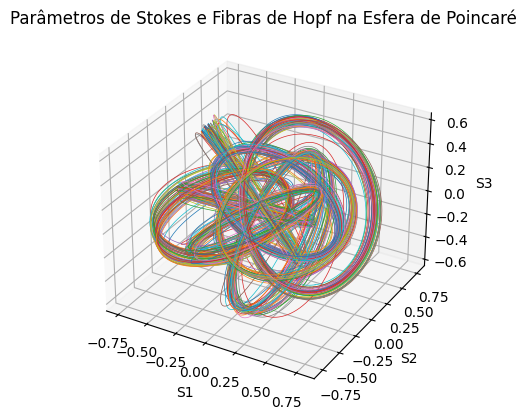

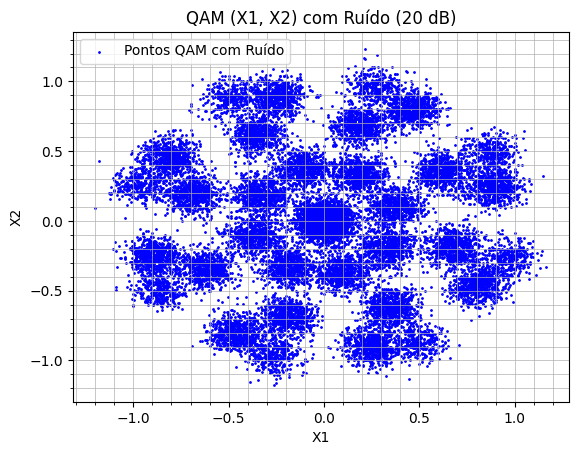

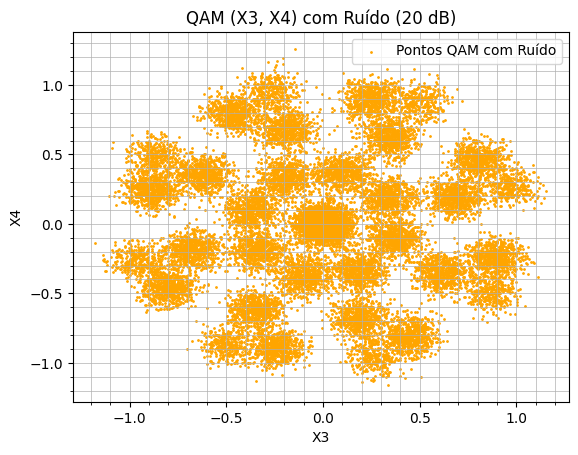

Foram aplicadas 342 iterações de ruído nos pontos QAM.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from matplotlib import colormaps
from sklearn.neighbors import KNeighborsClassifier

# Função para mapear a fibriação de Hopf
def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

# Gerando os pontos ótimos com ruído
m = 8
bits = np.random.randint(0, 2, 1026)
phi = []
E_x = []
E_y = []
S0 = []
S1 = []
S2 = []
S3 = []

# Mapeamento de bits para valores E_x, E_y e phi
for i in range(0, len(bits), 3):
    bits_entrada = bits[i:i+3]
    if np.array_equal(bits_entrada, [0, 0, 0]):
        E_x.append(0.8966)
        phi0 = 40.06 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4428 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 0, 1]):
        E_x.append(0.4428)
        phi0 = 40.06 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8966 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 1, 0]):
        E_x.append(0.8966)
        phi0 = 139.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4428 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 1, 1]):
        E_x.append(0.4428)
        phi0 = 139.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8966 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 0, 0]):
        E_x.append(0.9642)
        phi0 = -90 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.2649 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 0, 1]):
        E_x.append(0.2649)
        phi0 = -90 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.9642 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 1, 0]):
        E_x.append(0.7071)
        phi0 = -30.73 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.7071 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 1, 1]):
        E_x.append(0.7071)
        phi0 = -149.27 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.7071 * np.exp(1j * phi0))

# Adição de ruído
SNR = 20 # dB
SNR_Lin = 10**(SNR / 10)
Pn = 1 / SNR_Lin
Pnx = Pn / 2
Pny = Pn / 2

E_x = np.array(E_x) + np.sqrt(Pnx / 2) * (np.random.randn(len(E_x)) + 1j * np.random.randn(len(E_x)))
E_y = np.array(E_y) + np.sqrt(Pny / 2) * (np.random.randn(len(E_y)) + 1j * np.random.randn(len(E_y)))

# Cálculo dos parâmetros de Stokes
for i in range(len(E_x)):
    S0.append(abs(E_x[i])**2 + abs(E_y[i])**2)
    S1.append(abs(E_x[i])**2 - abs(E_y[i])**2)
    S2.append(2 * np.real(E_x[i] * np.conj(E_y[i])))
    S3.append(-2 * np.imag(E_x[i] * np.conj(E_y[i])))

S0 = np.array(S0)
S1 = np.array(S1)
S2 = np.array(S2)
S3 = np.array(S3)

# Normalização dos parâmetros de Stokes
S0n = S0 / S0
S1n = S1 / S0
S2n = S2 / S0
S3n = S3 / S0

# QAM Points
X1 = []
X2 = []
X3 = []
X4 = []

varphi_vals = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi, 5*np.pi/4, 3*np.pi/2, 7*np.pi/4]

# Definindo os valores de theta e phi
theta_vals = [0.7853, 2.3561, -0.7853, -2.3561, 0.0, 3.1415, 1.5707, -1.5707]
phi_vals = [0.5364, 0.5364, 0.5364, 0.5364, -0.5364, -0.5364, -0.5364, -0.5364]

count = 0
for n in range(len(theta_vals)):
    theta = theta_vals[n]
    phi = phi_vals[n]
    for varphi in varphi_vals:
        count += 1
        X1.append(np.round(np.cos(theta / 2) * np.cos(varphi + phi / 2), 4))
        X2.append(np.round(np.cos(theta / 2) * np.sin(varphi + phi / 2), 4))
        X3.append(np.round(np.sin(theta / 2) * np.cos(varphi - phi / 2), 4))
        X4.append(np.round(np.sin(theta / 2) * np.sin(varphi - phi / 2), 4))

print(f'\n\nForam realizadas {count} operações\n\n')

# Visualização na Esfera de Poincaré
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Adicionando as fibras de Hopf
for i in range(len(S1n)):
    fx, fy, fz = hopfmap(S1n[i], S2n[i], S3n[i])
    ax.plot3D(fx, fy, fz, linewidth=0.5)

ax.set_xlabel('S1')
ax.set_ylabel('S2')
ax.set_zlabel('S3')
plt.title('Parâmetros de Stokes e Fibras de Hopf na Esfera de Poincaré')
plt.show()

# Configuração do SNR para os pontos QAM
SNR_QAM_Lin = 10**(SNR / 10)
Pn_QAM = 1 / SNR_QAM_Lin
sigma_QAM = np.sqrt(Pn_QAM / 2)  # Desvio padrão do ruído QAM

# Variáveis para os pontos QAM com ruído (em várias instâncias)
X1_noisy = []
X2_noisy = []
X3_noisy = []
X4_noisy = []

# Aplicar ruído iterativamente o mesmo número de vezes que na modulação 8PolSK
num_iteracoes = len(S1n)  # Número de fibras de Hopf geradas

for _ in range(num_iteracoes):
    # Adicionando ruído aos pontos QAM
    X1_noisy.append(np.array(X1) + sigma_QAM * (np.random.randn(len(X1)) + 1j * np.random.randn(len(X1))))
    X2_noisy.append(np.array(X2) + sigma_QAM * (np.random.randn(len(X2)) + 1j * np.random.randn(len(X2))))
    X3_noisy.append(np.array(X3) + sigma_QAM * (np.random.randn(len(X3)) + 1j * np.random.randn(len(X3))))
    X4_noisy.append(np.array(X4) + sigma_QAM * (np.random.randn(len(X4)) + 1j * np.random.randn(len(X4))))

# Combinar os resultados de todas as iterações para visualização conjunta
X1_noisy_combined = np.hstack(X1_noisy).real
X2_noisy_combined = np.hstack(X2_noisy).real
X3_noisy_combined = np.hstack(X3_noisy).real
X4_noisy_combined = np.hstack(X4_noisy).real

# Visualização dos pontos QAM dispersos pelo ruído
plt.figure(1)
plt.scatter(X1_noisy_combined, X2_noisy_combined, color='b', s=1, label='Pontos QAM com Ruído')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()
plt.title('QAM (X1, X2) com Ruído (20 dB)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()

plt.figure(2)
plt.scatter(X3_noisy_combined, X4_noisy_combined, color='orange', s=1, label='Pontos QAM com Ruído')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()
plt.title('QAM (X3, X4) com Ruído (20 dB)')
plt.xlabel('X3')
plt.ylabel('X4')
plt.legend()

plt.show()

# Exibindo a quantidade de iterações realizadas
print(f"Foram aplicadas {num_iteracoes} iterações de ruído nos pontos QAM.")

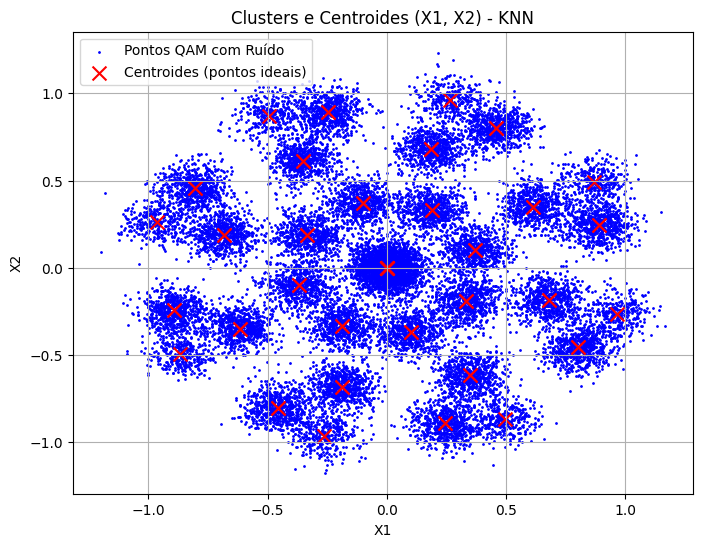

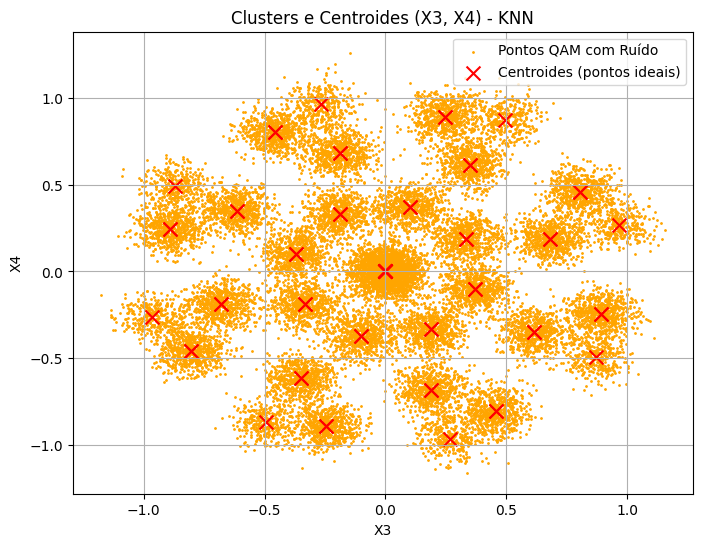

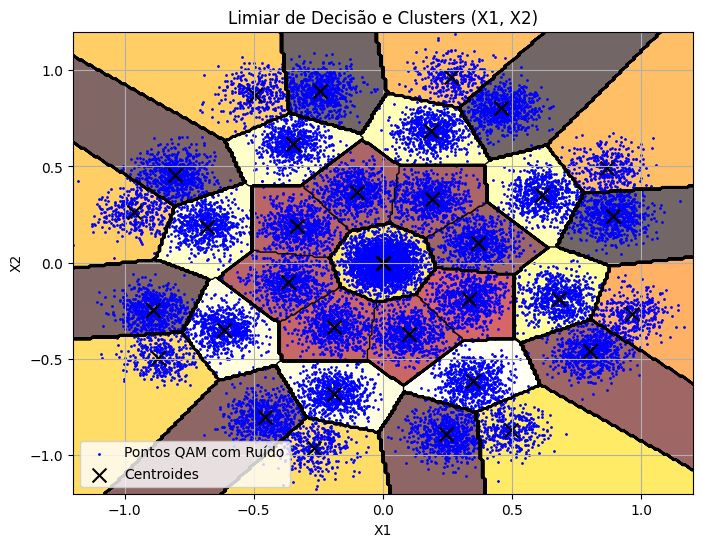

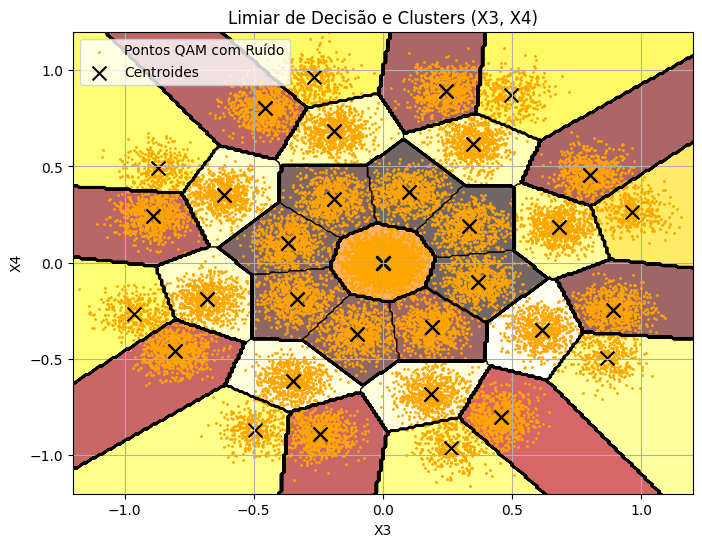

In [ ]:
# Criando os rótulos ideais (um rótulo para cada ponto QAM ideal)
labels_knn_qam1 = np.arange(len(X1))  # 0, 1, 2, ..., M-1 (M = pontos da constelação)
labels_knn_qam2 = np.arange(len(X3))

# Repetindo os rótulos para o número de iterações (supervisionado)
labels_true1 = np.tile(labels_knn_qam1, num_iteracoes)
labels_true2 = np.tile(labels_knn_qam2, num_iteracoes)


# Dados combinados para clustering
data_qam1 = np.vstack((X1_noisy_combined, X2_noisy_combined)).T  # (X1, X2)
data_qam2 = np.vstack((X3_noisy_combined, X4_noisy_combined)).T  # (X3, X4)

# Criando os rótulos para os pontos QAM ideais
labels_knn_qam1 = np.arange(len(X1))
labels_knn_qam2 = np.arange(len(X3))

# Preparando os dados de treino (QAM sem ruído)
train_qam1 = np.vstack((X1, X2)).T
train_qam2 = np.vstack((X3, X4)).T

# Definindo número de vizinhos
k = 5

# Aplicando KNN nos dados (X1, X2)
knn_qam1 = KNeighborsClassifier(n_neighbors=k)
knn_qam1.fit(train_qam1, labels_knn_qam1)
pred_labels_qam1 = knn_qam1.predict(data_qam1)

# Aplicando KNN nos dados (X3, X4)
knn_qam2 = KNeighborsClassifier(n_neighbors=k)
knn_qam2.fit(train_qam2, labels_knn_qam2)
pred_labels_qam2 = knn_qam2.predict(data_qam2)

# Repetir os rótulos para o número de iterações de ruído
labels_true1 = np.tile(labels_knn_qam1, num_iteracoes)
labels_true2 = np.tile(labels_knn_qam2, num_iteracoes)

# Cálculo dos "centroides" de cada classe (baseados nos pontos ideais, sem ruído)
centroids_qam1 = np.array([train_qam1[labels_knn_qam1 == i].mean(axis=0) for i in np.unique(labels_knn_qam1)])
centroids_qam2 = np.array([train_qam2[labels_knn_qam2 == i].mean(axis=0) for i in np.unique(labels_knn_qam2)])

# Visualização dos clusters e centroides para (X1, X2)
plt.figure(figsize=(8, 6))
plt.scatter(data_qam1[:, 0], data_qam1[:, 1], color='b', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam1[:, 0], centroids_qam1[:, 1], c='red', marker='x', s=100, label='Centroides (pontos ideais)')
plt.title('Clusters e Centroides (X1, X2) - KNN')
plt.xlabel('X1')
plt.ylabel('X2')
plt.grid(True)
plt.legend()

# Visualização dos clusters e centroides para (X3, X4)
plt.figure(figsize=(8, 6))
plt.scatter(data_qam2[:, 0], data_qam2[:, 1], color='orange', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam2[:, 0], centroids_qam2[:, 1], c='red', marker='x', s=100, label='Centroides (pontos ideais)')
plt.title('Clusters e Centroides (X3, X4) - KNN')
plt.xlabel('X3')
plt.ylabel('X4')
plt.grid(True)
plt.legend()

plt.show()
# Função para calcular o limiar de decisão
def decision_boundary(X, Y, centroids):
    distances = cdist(np.c_[X.ravel(), Y.ravel()], centroids, 'euclidean')
    labels = np.argmin(distances, axis=1).reshape(X.shape)
    return labels

# Criando uma grade para visualizar os limiares de decisão
x_min, x_max = data_qam1[:, 0].min() - 1, data_qam1[:, 0].max() + 1
y_min, y_max = data_qam1[:, 1].min() - 1, data_qam1[:, 1].max() + 1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

# Calcular os limiares de decisão para (X1, X2)
decision_labels_qam1 = decision_boundary(xx, yy, centroids_qam1)

# Visualização do limiar de decisão para (X1, X2)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, decision_labels_qam1, levels=30, alpha=0.6, cmap='hot')
plt.contour(xx, yy, decision_labels_qam1, levels=np.arange(len(centroids_qam1) + 1) - 0.5, colors='black', linewidths=1)
plt.scatter(data_qam1[:, 0], data_qam1[:, 1], color='b', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam1[:, 0], centroids_qam1[:, 1], c='black', marker='x', s=100, label='Centroides')
plt.title('Limiar de Decisão e Clusters (X1, X2)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.grid(True)
plt.legend()

# Calcular os limiares de decisão para (X3, X4)
decision_labels_qam2 = decision_boundary(xx, yy, centroids_qam2)

# Visualização do limiar de decisão para (X3, X4)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, decision_labels_qam2, levels=30, alpha=0.6, cmap='hot')
plt.contour(xx, yy, decision_labels_qam2, levels=np.arange(len(centroids_qam2) + 1) - 0.5, colors='black', linewidths=1)
plt.scatter(data_qam2[:, 0], data_qam2[:, 1], color='orange', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam2[:, 0], centroids_qam2[:, 1], c='black', marker='x', s=100, label='Centroides')
plt.title('Limiar de Decisão e Clusters (X3, X4)')
plt.xlabel('X3')
plt.ylabel('X4')
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.grid(True)
plt.legend()

plt.show()



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score,precision_score, recall_score, f1_score
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
import numpy as np


# 1. Rótulos verdadeiros (0 a 30) para cada ponto sem ruído, repetidos por iteração
n_points = len(X1)
true_labels_qam1 = np.tile(np.arange(n_points), num_iteracoes)
true_labels_qam2 = np.tile(np.arange(n_points), num_iteracoes)

# 2. Atribuição do rótulo ideal ao ponto ruidoso mais próximo (como verdade "reconhecida")
def assign_true_labels(noisy_data, clean_constellation):
    distances = cdist(noisy_data, clean_constellation)
    return np.argmin(distances, axis=1)

qam1_clean = np.vstack((X1, X2)).T
qam2_clean = np.vstack((X3, X4)).T

matched_labels_qam1 = assign_true_labels(data_qam1, qam1_clean)
matched_labels_qam2 = assign_true_labels(data_qam2, qam2_clean)

# 3. Remapeamento dos rótulos do KMeans com Hungarian Algorithm (scipy)
def remap_labels(true_labels, pred_labels):
    D = max(true_labels.max(), pred_labels.max()) + 1
    cost_matrix = np.zeros((D, D), dtype=np.int64)
    for i in range(len(true_labels)):
        cost_matrix[true_labels[i], pred_labels[i]] += 1
    row_ind, col_ind = linear_sum_assignment(-cost_matrix)  # Maximiza os acertos
    mapping = {col: row for row, col in zip(row_ind, col_ind)}
    new_preds = np.array([mapping.get(label, label) for label in pred_labels])
    return new_preds

# Aplicar remapeamento
labels_qam1_mapped = remap_labels(matched_labels_qam1, labels_qam1)
labels_qam2_mapped = remap_labels(matched_labels_qam2, labels_qam2)

# 4. Métricas para QAM1
print("=== Métricas para QAM (X1, X2) ===")
print("Acurácia:", accuracy_score(matched_labels_qam1, labels_qam1_mapped))
print("Precisão (macro):", precision_score(matched_labels_qam1, labels_qam1_mapped, average='macro', zero_division=0))
print("Precisão (micro):", precision_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))
print("Recall", recall_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))
print("F1 Score", f1_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))

# 5. Métricas para QAM2
print("=== Métricas para QAM (X3, X4) ===")
print("Acurácia:", accuracy_score(matched_labels_qam2, labels_qam2_mapped))
print("Precisão (macro):", precision_score(matched_labels_qam2, labels_qam2_mapped, average='macro', zero_division=0))
print("Precisão (micro):", precision_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))
print("Recall", recall_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))
print("F1 Score", f1_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))

=== Métricas para QAM (X1, X2) ===
Acurácia: 0.9413834064327485
Precisão (macro): 0.9154151160730107
Precisão (micro): 0.9413834064327485
Recall 0.9413834064327485
F1 Score 0.9413834064327485
=== Métricas para QAM (X3, X4) ===
Acurácia: 0.9390076754385965
Precisão (macro): 0.9117306101955225
Precisão (micro): 0.9390076754385965
Recall 0.9390076754385965
F1 Score 0.9390076754385965


# Random forest 8 pontos com ruido



Foram realizadas 64 operações




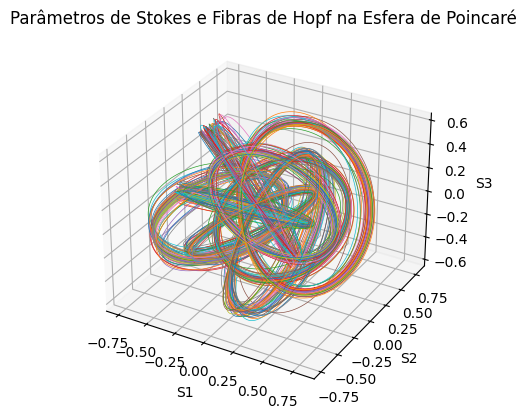

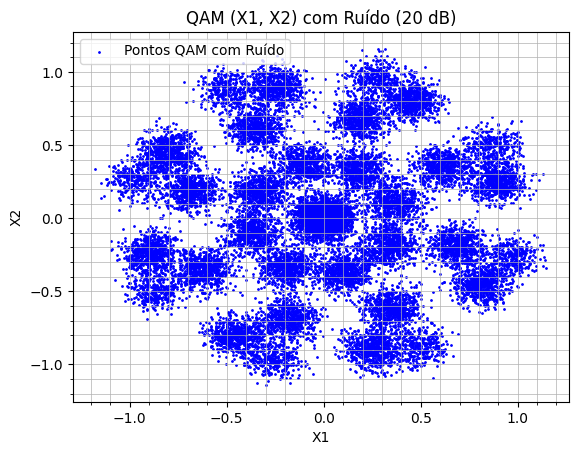

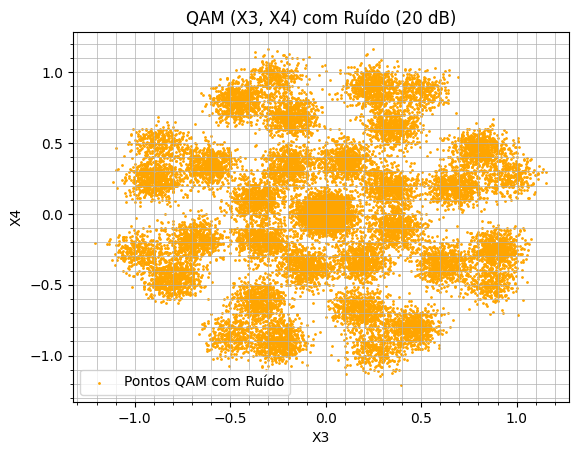

Foram aplicadas 342 iterações de ruído nos pontos QAM.


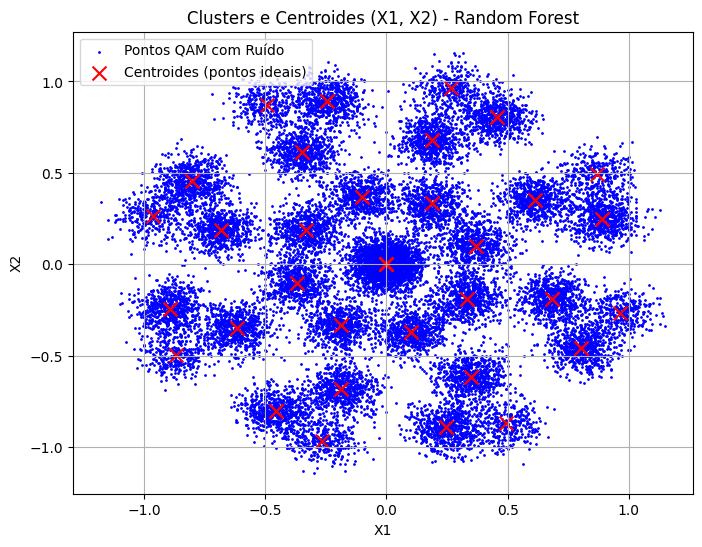

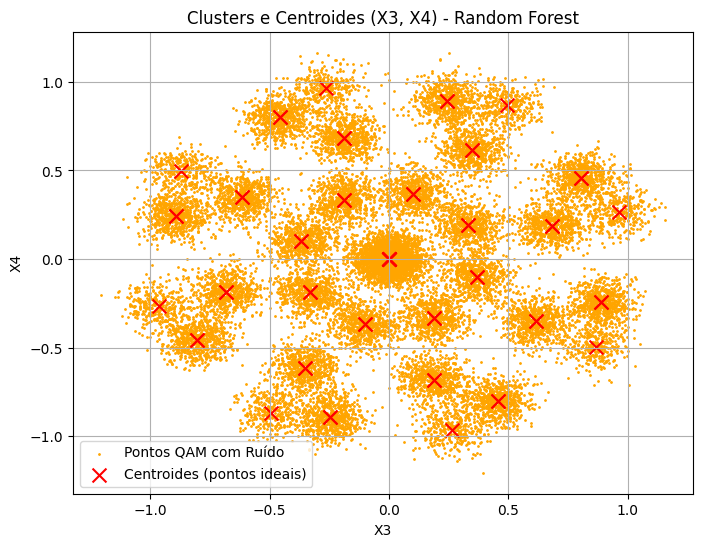

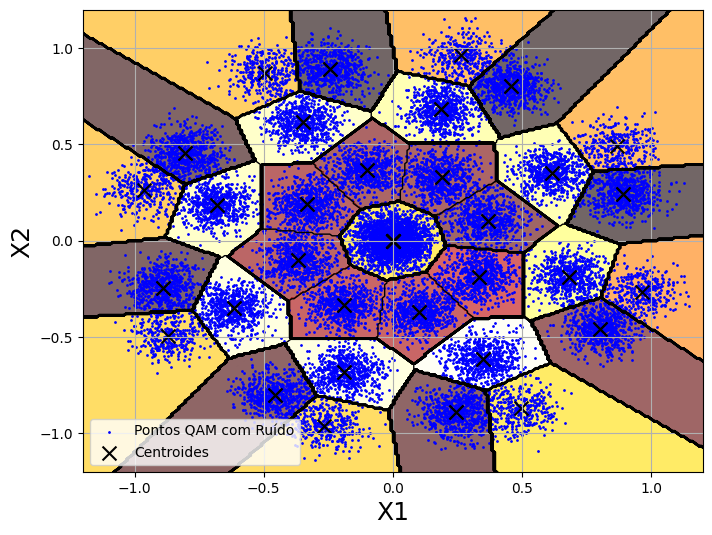

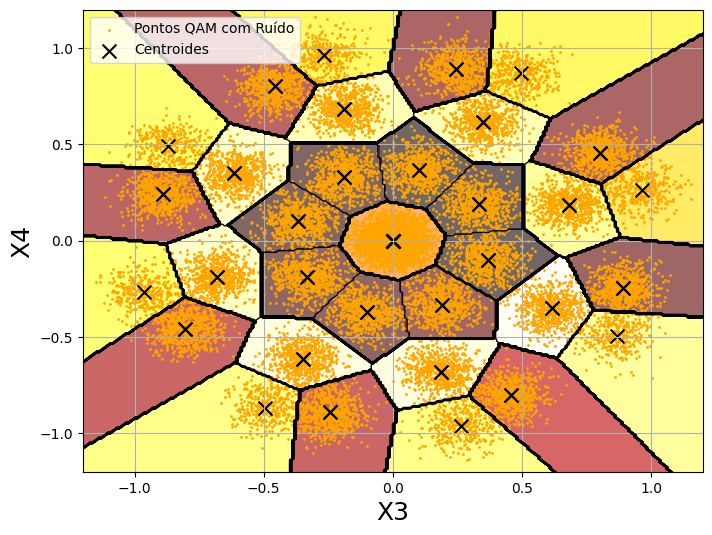

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from matplotlib import colormaps
from sklearn.ensemble import RandomForestClassifier

# Função para mapear a fibriação de Hopf
def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

# Gerando os pontos ótimos com ruído
m = 8
bits = np.random.randint(0, 2, 1026)
phi = []
E_x = []
E_y = []
S0 = []
S1 = []
S2 = []
S3 = []

# Mapeamento de bits para valores E_x, E_y e phi
for i in range(0, len(bits), 3):
    bits_entrada = bits[i:i+3]
    if np.array_equal(bits_entrada, [0, 0, 0]):
        E_x.append(0.8966)
        phi0 = 40.06 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4428 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 0, 1]):
        E_x.append(0.4428)
        phi0 = 40.06 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8966 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 1, 0]):
        E_x.append(0.8966)
        phi0 = 139.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4428 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [0, 1, 1]):
        E_x.append(0.4428)
        phi0 = 139.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8966 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 0, 0]):
        E_x.append(0.9642)
        phi0 = -90 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.2649 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 0, 1]):
        E_x.append(0.2649)
        phi0 = -90 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.9642 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 1, 0]):
        E_x.append(0.7071)
        phi0 = -30.73 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.7071 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 1, 1]):
        E_x.append(0.7071)
        phi0 = -149.27 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.7071 * np.exp(1j * phi0))

# Adição de ruído
SNR = 20 # dB
SNR_Lin = 10**(SNR / 10)
Pn = 1 / SNR_Lin
Pnx = Pn / 2
Pny = Pn / 2

E_x = np.array(E_x) + np.sqrt(Pnx / 2) * (np.random.randn(len(E_x)) + 1j * np.random.randn(len(E_x)))
E_y = np.array(E_y) + np.sqrt(Pny / 2) * (np.random.randn(len(E_y)) + 1j * np.random.randn(len(E_y)))

# Cálculo dos parâmetros de Stokes
for i in range(len(E_x)):
    S0.append(abs(E_x[i])**2 + abs(E_y[i])**2)
    S1.append(abs(E_x[i])**2 - abs(E_y[i])**2)
    S2.append(2 * np.real(E_x[i] * np.conj(E_y[i])))
    S3.append(-2 * np.imag(E_x[i] * np.conj(E_y[i])))

S0 = np.array(S0)
S1 = np.array(S1)
S2 = np.array(S2)
S3 = np.array(S3)

# Normalização dos parâmetros de Stokes
S0n = S0 / S0
S1n = S1 / S0
S2n = S2 / S0
S3n = S3 / S0

# QAM Points
X1 = []
X2 = []
X3 = []
X4 = []

varphi_vals = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi, 5*np.pi/4, 3*np.pi/2, 7*np.pi/4]

# Definindo os valores de theta e phi
theta_vals = [0.7853, 2.3561, -0.7853, -2.3561, 0.0, 3.1415, 1.5707, -1.5707]
phi_vals = [0.5364, 0.5364, 0.5364, 0.5364, -0.5364, -0.5364, -0.5364, -0.5364]

count = 0
for n in range(len(theta_vals)):
    theta = theta_vals[n]
    phi = phi_vals[n]
    for varphi in varphi_vals:
        count += 1
        X1.append(np.round(np.cos(theta / 2) * np.cos(varphi + phi / 2), 4))
        X2.append(np.round(np.cos(theta / 2) * np.sin(varphi + phi / 2), 4))
        X3.append(np.round(np.sin(theta / 2) * np.cos(varphi - phi / 2), 4))
        X4.append(np.round(np.sin(theta / 2) * np.sin(varphi - phi / 2), 4))

print(f'\n\nForam realizadas {count} operações\n\n')

# Visualização na Esfera de Poincaré
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Adicionando as fibras de Hopf
for i in range(len(S1n)):
    fx, fy, fz = hopfmap(S1n[i], S2n[i], S3n[i])
    ax.plot3D(fx, fy, fz, linewidth=0.5)

ax.set_xlabel('S1')
ax.set_ylabel('S2')
ax.set_zlabel('S3')
plt.title('Parâmetros de Stokes e Fibras de Hopf na Esfera de Poincaré')
plt.show()

# Configuração do SNR para os pontos QAM
SNR_QAM_Lin = 10**(SNR / 10)
Pn_QAM = 1 / SNR_QAM_Lin
sigma_QAM = np.sqrt(Pn_QAM / 2)  # Desvio padrão do ruído QAM

# Variáveis para os pontos QAM com ruído (em várias instâncias)
X1_noisy = []
X2_noisy = []
X3_noisy = []
X4_noisy = []

# Aplicar ruído iterativamente o mesmo número de vezes que na modulação 8PolSK
num_iteracoes = len(S1n)  # Número de fibras de Hopf geradas

for _ in range(num_iteracoes):
    # Adicionando ruído aos pontos QAM
    X1_noisy.append(np.array(X1) + sigma_QAM * (np.random.randn(len(X1)) + 1j * np.random.randn(len(X1))))
    X2_noisy.append(np.array(X2) + sigma_QAM * (np.random.randn(len(X2)) + 1j * np.random.randn(len(X2))))
    X3_noisy.append(np.array(X3) + sigma_QAM * (np.random.randn(len(X3)) + 1j * np.random.randn(len(X3))))
    X4_noisy.append(np.array(X4) + sigma_QAM * (np.random.randn(len(X4)) + 1j * np.random.randn(len(X4))))

# Combinar os resultados de todas as iterações para visualização conjunta
X1_noisy_combined = np.hstack(X1_noisy).real
X2_noisy_combined = np.hstack(X2_noisy).real
X3_noisy_combined = np.hstack(X3_noisy).real
X4_noisy_combined = np.hstack(X4_noisy).real

# Visualização dos pontos QAM dispersos pelo ruído
plt.figure(1)
plt.scatter(X1_noisy_combined, X2_noisy_combined, color='b', s=1, label='Pontos QAM com Ruído')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()
plt.title('QAM (X1, X2) com Ruído (20 dB)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()

plt.figure(2)
plt.scatter(X3_noisy_combined, X4_noisy_combined, color='orange', s=1, label='Pontos QAM com Ruído')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()
plt.title('QAM (X3, X4) com Ruído (20 dB)')
plt.xlabel('X3')
plt.ylabel('X4')
plt.legend()

plt.show()

# Exibindo a quantidade de iterações realizadas
print(f"Foram aplicadas {num_iteracoes} iterações de ruído nos pontos QAM.")


# Dados combinados para clustering
data_qam1 = np.vstack((X1_noisy_combined, X2_noisy_combined)).T  # (X1, X2)
data_qam2 = np.vstack((X3_noisy_combined, X4_noisy_combined)).T  # (X3, X4)

# Número de clusters (igual ao número de pontos na constelação QAM original)
n_clusters = 32

# Dados combinados para clustering
data_qam1 = np.vstack((X1_noisy_combined, X2_noisy_combined)).T  # (X1, X2)
data_qam2 = np.vstack((X3_noisy_combined, X4_noisy_combined)).T  # (X3, X4)

# Criando os rótulos para os pontos QAM ideais
labels_rf_qam1 = np.arange(len(X1))
labels_rf_qam2 = np.arange(len(X3))

# Preparando os dados de treino (QAM sem ruído)
train_qam1 = np.vstack((X1, X2)).T
train_qam2 = np.vstack((X3, X4)).T

# Criando o classificador Random Forest
rf_qam1 = RandomForestClassifier(n_estimators=100, random_state=42)
rf_qam2 = RandomForestClassifier(n_estimators=100, random_state=42)

# Treinando o classificador
rf_qam1.fit(train_qam1, labels_rf_qam1)
rf_qam2.fit(train_qam2, labels_rf_qam2)

# Classificando os dados ruidosos
pred_labels_qam1 = rf_qam1.predict(data_qam1)
pred_labels_qam2 = rf_qam2.predict(data_qam2)

# Repetir os rótulos para o número de iterações de ruído
labels_true1 = np.tile(labels_rf_qam1, num_iteracoes)
labels_true2 = np.tile(labels_rf_qam2, num_iteracoes)

# Cálculo dos "centroides" de cada classe (baseados nos pontos ideais, sem ruído)
centroids_qam1 = np.array([train_qam1[labels_rf_qam1 == i].mean(axis=0) for i in np.unique(labels_rf_qam1)])
centroids_qam2 = np.array([train_qam2[labels_rf_qam2 == i].mean(axis=0) for i in np.unique(labels_rf_qam2)])

# Visualização dos clusters e centroides para (X1, X2)
plt.figure(figsize=(8, 6))
plt.scatter(data_qam1[:, 0], data_qam1[:, 1], color='blue', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam1[:, 0], centroids_qam1[:, 1], c='red', marker='x', s=100, label='Centroides (pontos ideais)')
plt.title('Clusters e Centroides (X1, X2) - Random Forest')
plt.xlabel('X1')
plt.ylabel('X2')
plt.grid(True)
plt.legend()

# Visualização dos clusters e centroides para (X3, X4)
plt.figure(figsize=(8, 6))
plt.scatter(data_qam2[:, 0], data_qam2[:, 1], color='orange', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam2[:, 0], centroids_qam2[:, 1], c='red', marker='x', s=100, label='Centroides (pontos ideais)')
plt.title('Clusters e Centroides (X3, X4) - Random Forest')
plt.xlabel('X3')
plt.ylabel('X4')
plt.grid(True)
plt.legend()

plt.show()


# Função para calcular o limiar de decisão
def decision_boundary(X, Y, centroids):
    distances = cdist(np.c_[X.ravel(), Y.ravel()], centroids, 'euclidean')
    labels = np.argmin(distances, axis=1).reshape(X.shape)
    return labels

# Criando uma grade para visualizar os limiares de decisão
x_min, x_max = data_qam1[:, 0].min() - 1, data_qam1[:, 0].max() + 1
y_min, y_max = data_qam1[:, 1].min() - 1, data_qam1[:, 1].max() + 1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

# Calcular os limiares de decisão para (X1, X2)
decision_labels_qam1 = decision_boundary(xx, yy, centroids_qam1)

# Visualização do limiar de decisão para (X1, X2)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, decision_labels_qam1, levels=30, alpha=0.6, cmap='hot')
plt.contour(xx, yy, decision_labels_qam1, levels=np.arange(len(centroids_qam1) + 1) - 0.5, colors='black', linewidths=1)
plt.scatter(data_qam1[:, 0], data_qam1[:, 1], color='blue', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam1[:, 0], centroids_qam1[:, 1], c='black', marker='x', s=100, label='Centroides')
plt.title('') #Limiar de Decisão e Clusters (X1, X2)
plt.xlabel('X1', fontsize=18)
plt.ylabel('X2', fontsize=18)
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.grid(True)
plt.legend()

# Calcular os limiares de decisão para (X3, X4)
decision_labels_qam2 = decision_boundary(xx, yy, centroids_qam2)

# Visualização do limiar de decisão para (X3, X4)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, decision_labels_qam2, levels=30, alpha=0.6, cmap='hot')
plt.contour(xx, yy, decision_labels_qam2, levels=np.arange(len(centroids_qam2) + 1) - 0.5, colors='black', linewidths=1)
plt.scatter(data_qam2[:, 0], data_qam2[:, 1], color='orange', s=1, label='Pontos QAM com Ruído')
plt.scatter(centroids_qam2[:, 0], centroids_qam2[:, 1], c='black', marker='x', s=100, label='Centroides')
plt.title('')#Limiar de Decisão e Clusters (X3, X4)
plt.xlabel('X3', fontsize=18)
plt.ylabel('X4', fontsize=18)
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.grid(True)
plt.legend()

plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score,precision_score, recall_score, f1_score
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
import numpy as np


# 1. Rótulos verdadeiros (0 a 30) para cada ponto sem ruído, repetidos por iteração
n_points = len(X1)
true_labels_qam1 = np.tile(np.arange(n_points), num_iteracoes)
true_labels_qam2 = np.tile(np.arange(n_points), num_iteracoes)

# 2. Atribuição do rótulo ideal ao ponto ruidoso mais próximo (como verdade "reconhecida")
def assign_true_labels(noisy_data, clean_constellation):
    distances = cdist(noisy_data, clean_constellation)
    return np.argmin(distances, axis=1)

qam1_clean = np.vstack((X1, X2)).T
qam2_clean = np.vstack((X3, X4)).T

matched_labels_qam1 = assign_true_labels(data_qam1, qam1_clean)
matched_labels_qam2 = assign_true_labels(data_qam2, qam2_clean)

# 3. Remapeamento dos rótulos do KMeans com Hungarian Algorithm (scipy)
def remap_labels(true_labels, pred_labels):
    D = max(true_labels.max(), pred_labels.max()) + 1
    cost_matrix = np.zeros((D, D), dtype=np.int64)
    for i in range(len(true_labels)):
        cost_matrix[true_labels[i], pred_labels[i]] += 1
    row_ind, col_ind = linear_sum_assignment(-cost_matrix)  # Maximiza os acertos
    mapping = {col: row for row, col in zip(row_ind, col_ind)}
    new_preds = np.array([mapping.get(label, label) for label in pred_labels])
    return new_preds

# Aplicar remapeamento
labels_qam1_mapped = remap_labels(matched_labels_qam1, labels_qam1)
labels_qam2_mapped = remap_labels(matched_labels_qam2, labels_qam2)

# 4. Métricas para QAM1
print("=== Métricas para QAM (X1, X2) ===")
print("Acurácia:", accuracy_score(matched_labels_qam1, labels_qam1_mapped))
print("Precisão (macro):", precision_score(matched_labels_qam1, labels_qam1_mapped, average='macro', zero_division=0))
print("Precisão (micro):", precision_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))
print("Recall", recall_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))
print("F1 Score", f1_score(matched_labels_qam1, labels_qam1_mapped, average='micro', zero_division=0))

# 5. Métricas para QAM2
print("=== Métricas para QAM (X3, X4) ===")
print("Acurácia:", accuracy_score(matched_labels_qam2, labels_qam2_mapped))
print("Precisão (macro):", precision_score(matched_labels_qam2, labels_qam2_mapped, average='macro', zero_division=0))
print("Precisão (micro):", precision_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))
print("Recall", recall_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))
print("F1 Score", f1_score(matched_labels_qam2, labels_qam2_mapped, average='micro', zero_division=0))


NameError: name 'labels_qam1' is not defined

# 4 Pontos Ótimos Com Ruído


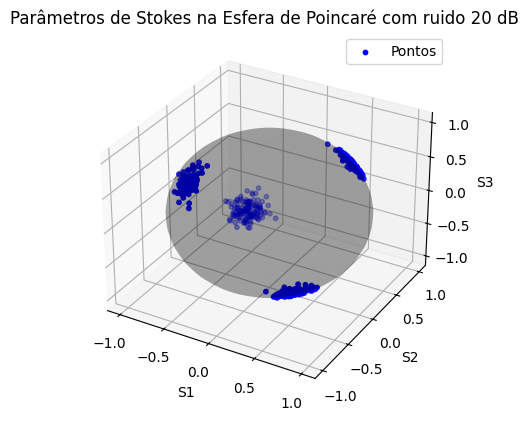

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros iniciais
m = 8
bits = np.random.randint(0, 2, 1026)
phi = []
E_x = []
E_y = []
S0 = []
S1 = []
S2 = []
S3 = []
colorlist = np.random.rand(16, 3)

# Mapeamento de bits para valores E_x, E_y e phi
for i in range(0, len(bits), 2):
    bits_entrada = bits[i:i+2]
    if np.array_equal(bits_entrada, [0, 0]):
        E_x.append(0.8881)
        phi0 = -135 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4597 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [ 0, 1]):
        E_x.append(0.8881  )
        phi0 = 45 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4597 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 0]):
        E_x.append(0.4597  )
        phi0 = 135* np.pi / 180
        phi.append(phi0)
        E_y.append(0.8881 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [ 1, 1]):
        E_x.append(0.4597  )
        phi0 = -45 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8881 * np.exp(1j * phi0))


# Adição de ruído
SNR = 20  # dB
SNR_Lin = 10**(SNR / 10)
Pn = 1 / SNR_Lin
Pnx = Pn / 2
Pny = Pn / 2

E_x = np.array(E_x) + np.sqrt(Pnx / 2) * (np.random.randn(len(E_x)) + 1j * np.random.randn(len(E_x)))
E_y = np.array(E_y) + np.sqrt(Pny / 2) * (np.random.randn(len(E_y)) + 1j * np.random.randn(len(E_y)))

# Cálculo dos parâmetros de Stokes
for i in range(len(E_x)):
    S0.append(abs(E_x[i])**2 + abs(E_y[i])**2)
    S1.append(abs(E_x[i])**2 - abs(E_y[i])**2)
    S2.append(2 * np.real(E_x[i] * np.conj(E_y[i])))
    S3.append(-2 * np.imag(E_x[i] * np.conj(E_y[i])))

S0 = np.array(S0)
S1 = np.array(S1)
S2 = np.array(S2)
S3 = np.array(S3)

# Normalização dos parâmetros de Stokes
S0n = S0 / S0
S1n = S1 / S0
S2n = S2 / S0
S3n = S3 / S0

# Esfera de Poincaré
t = np.linspace(-np.pi, np.pi, 40)
s = np.linspace(-np.pi, np.pi, 40)
x = np.outer(np.cos(t), np.sin(s))
y = np.outer(np.sin(t), np.sin(s))
z = np.outer(np.ones(len(t)), np.cos(s))

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x, y, z, color='k', alpha=0.1)
ax.scatter(S1n, S2n, S3n, color='b', label='Pontos', s=10)
ax.grid(True)
ax.set_xlabel('S1')
ax.set_ylabel('S2')
ax.set_zlabel('S3')
plt.title('Parâmetros de Stokes na Esfera de Poincaré com ruido 20 dB')
plt.legend()
plt.show()

# print( S1n, S2n, S3n)




Foram realizadas 32 operações




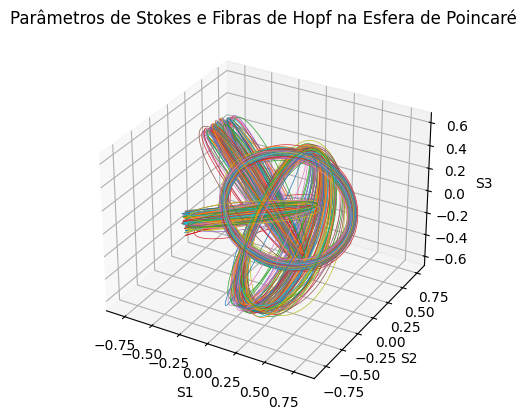

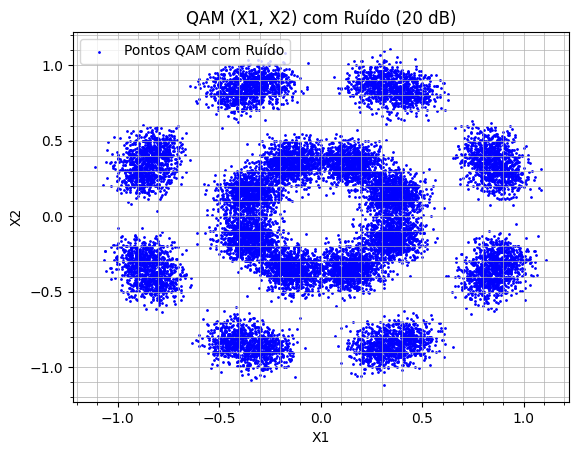

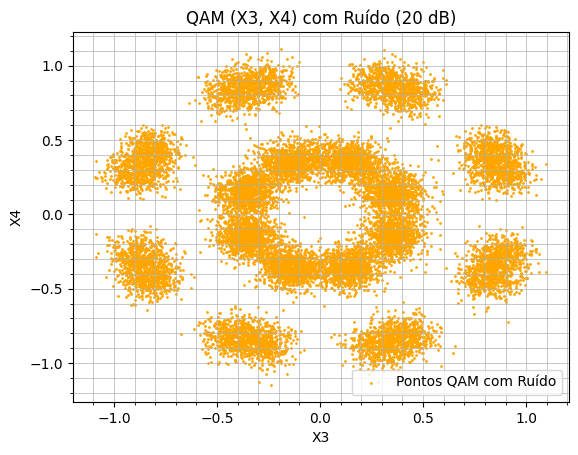

Foram aplicadas 513 iterações de ruído nos pontos QAM.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from matplotlib import colormaps

# Função para mapear a fibriação de Hopf
def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

# Gerando os pontos ótimos com ruído
m = 8
bits = np.random.randint(0, 2, 1026)
phi = []
E_x = []
E_y = []
S0 = []
S1 = []
S2 = []
S3 = []

# Mapeamento de bits para valores E_x, E_y e phi
for i in range(0, len(bits), 2):
    bits_entrada = bits[i:i+2]
    if np.array_equal(bits_entrada, [0, 0]):
        E_x.append(0.8881)
        phi0 = -135 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4597 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [ 0, 1]):
        E_x.append(0.8881  )
        phi0 = 45 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4597 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [1, 0]):
        E_x.append(0.4597  )
        phi0 = 135* np.pi / 180
        phi.append(phi0)
        E_y.append(0.8881 * np.exp(1j * phi0))
    elif np.array_equal(bits_entrada, [ 1, 1]):
        E_x.append(0.4597  )
        phi0 = -45 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8881 * np.exp(1j * phi0))

# Adição de ruído
SNR = 20  # dB
SNR_Lin = 10**(SNR / 10)
Pn = 1 / SNR_Lin
Pnx = Pn / 2
Pny = Pn / 2

E_x = np.array(E_x) + np.sqrt(Pnx / 2) * (np.random.randn(len(E_x)) + 1j * np.random.randn(len(E_x)))
E_y = np.array(E_y) + np.sqrt(Pny / 2) * (np.random.randn(len(E_y)) + 1j * np.random.randn(len(E_y)))

# Cálculo dos parâmetros de Stokes
for i in range(len(E_x)):
    S0.append(abs(E_x[i])**2 + abs(E_y[i])**2)
    S1.append(abs(E_x[i])**2 - abs(E_y[i])**2)
    S2.append(2 * np.real(E_x[i] * np.conj(E_y[i])))
    S3.append(-2 * np.imag(E_x[i] * np.conj(E_y[i])))

S0 = np.array(S0)
S1 = np.array(S1)
S2 = np.array(S2)
S3 = np.array(S3)

# Normalização dos parâmetros de Stokes
S0n = S0 / S0
S1n = S1 / S0
S2n = S2 / S0
S3n = S3 / S0

# QAM Points
X1 = []
X2 = []
X3 = []
X4 = []

varphi_vals = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi, 5*np.pi/4, 3*np.pi/2, 7*np.pi/4]

# Definindo os valores de theta e phi
theta_vals = [0.7853981633974483,-0.7853981633974483,2.356194490192345,-2.356194490192345]
phi_vals = [0.6154797086703874,-0.6154797086703874,-0.6154797086703874,0.6154797086703874]


count = 0
for n in range(len(theta_vals)):
    theta = theta_vals[n]
    phi = phi_vals[n]
    for varphi in varphi_vals:
        count += 1
        X1.append(np.round(np.cos(theta / 2) * np.cos(varphi + phi / 2), 4))
        X2.append(np.round(np.cos(theta / 2) * np.sin(varphi + phi / 2), 4))
        X3.append(np.round(np.sin(theta / 2) * np.cos(varphi - phi / 2), 4))
        X4.append(np.round(np.sin(theta / 2) * np.sin(varphi - phi / 2), 4))

print(f'\n\nForam realizadas {count} operações\n\n')

#esse pedaço ignora os pontos (0,0)
# count = 0
# for n in range(len(theta_vals)):
#     theta = theta_vals[n]
#     phi = phi_vals[n]
#     for varphi in varphi_vals:
#         count += 1
#         x1 = np.round(np.cos(theta / 2) * np.cos(varphi + phi / 2), 4)
#         x2 = np.round(np.cos(theta / 2) * np.sin(varphi + phi / 2), 4)
#         x3 = np.round(np.sin(theta / 2) * np.cos(varphi - phi / 2), 4)
#         x4 = np.round(np.sin(theta / 2) * np.sin(varphi - phi / 2), 4)

#         # Apenas adiciona se não for (0, 0)
#         if not (x1 == 0 and x2 == 0):
#             X1.append(x1)
#             X2.append(x2)
#         if not (x3 == 0 and x4 == 0):
#             X3.append(x3)
#             X4.append(x4)

# print(f'\n\nForam realizadas {count} operações\n')
# print(f'{len(X1)} pontos válidos em (X1, X2)')
# print(f'{len(X3)} pontos válidos em (X3, X4)\n')

# Visualização na Esfera de Poincaré
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Adicionando as fibras de Hopf
for i in range(len(S1n)):
    fx, fy, fz = hopfmap(S1n[i], S2n[i], S3n[i])
    ax.plot3D(fx, fy, fz, linewidth=0.5)

ax.set_xlabel('S1')
ax.set_ylabel('S2')
ax.set_zlabel('S3')
plt.title('Parâmetros de Stokes e Fibras de Hopf na Esfera de Poincaré')
plt.show()

# Configuração do SNR para os pontos QAM

SNR_QAM_Lin = 10**(SNR / 10)
Pn_QAM = 1 / SNR_QAM_Lin
sigma_QAM = np.sqrt(Pn_QAM / 2)  # Desvio padrão do ruído QAM

# Variáveis para os pontos QAM com ruído (em várias instâncias)
X1_noisy = []
X2_noisy = []
X3_noisy = []
X4_noisy = []

# Aplicar ruído iterativamente o mesmo número de vezes que na modulação 8PolSK
num_iteracoes = len(S1n)  # Número de fibras de Hopf geradas

for _ in range(num_iteracoes):
    # Adicionando ruído aos pontos QAM
    X1_noisy.append(np.array(X1) + sigma_QAM * (np.random.randn(len(X1)) + 1j * np.random.randn(len(X1))))
    X2_noisy.append(np.array(X2) + sigma_QAM * (np.random.randn(len(X2)) + 1j * np.random.randn(len(X2))))
    X3_noisy.append(np.array(X3) + sigma_QAM * (np.random.randn(len(X3)) + 1j * np.random.randn(len(X3))))
    X4_noisy.append(np.array(X4) + sigma_QAM * (np.random.randn(len(X4)) + 1j * np.random.randn(len(X4))))

# Combinar os resultados de todas as iterações para visualização conjunta
X1_noisy_combined = np.hstack(X1_noisy).real
X2_noisy_combined = np.hstack(X2_noisy).real
X3_noisy_combined = np.hstack(X3_noisy).real
X4_noisy_combined = np.hstack(X4_noisy).real

# Visualização dos pontos QAM dispersos pelo ruído
plt.figure(1)
plt.scatter(X1_noisy_combined, X2_noisy_combined, color='b', s=1, label='Pontos QAM com Ruído')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()
plt.title('QAM (X1, X2) com Ruído (20 dB)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()

plt.figure(2)
plt.scatter(X3_noisy_combined, X4_noisy_combined, color='orange', s=1, label='Pontos QAM com Ruído')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()
plt.title('QAM (X3, X4) com Ruído (20 dB)')
plt.xlabel('X3')
plt.ylabel('X4')
plt.legend()

plt.show()

# Exibindo a quantidade de iterações realizadas
print(f"Foram aplicadas {num_iteracoes} iterações de ruído nos pontos QAM.")

# 16 Pontos Ótimos com ruido


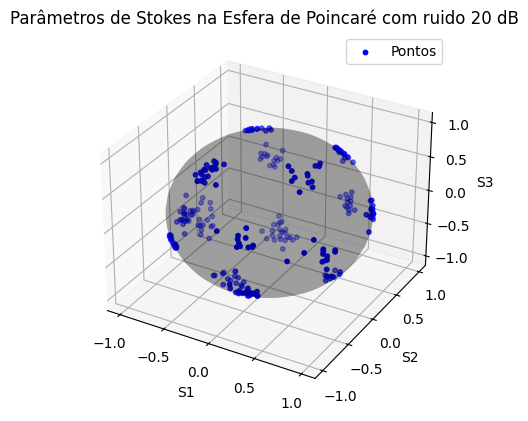

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros iniciais
# Gerando os pontos ótimos com ruído
m = 16
bits = np.random.randint(0, 2, 1024)

phi = []
E_x = []
E_y = []
S0 = []
S1 = []
S2 = []
S3 = []

# Mapeamento de bits para valores E_x, E_y e phi
for i in range(0, len(bits), 4):
    bits_entrada = bits[i:i+4]

    if np.array_equal(bits_entrada, [0,0,0,0]):
        E_x.append(0.8225)
        phi0 = 36.73 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.5688 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [0,0,0,1]):
        E_x.append(0.5518)
        phi0 = 123.61 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8340 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [0,0,1,0]):
        E_x.append(0.9009)
        phi0 = -85.85 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4339 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [0,0,1,1]):
        E_x.append(0.2519)
        phi0 = -71.99 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.9677 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [0,1,0,0]):
        E_x.append(0.7894)
        phi0 = -146.75 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.6138 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [0,1,0,1]):
        E_x.append(0.5969)
        phi0 = -106.38 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8023 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [0,1,1,0]):
        E_x.append(0.5010)
        phi0 = 6.08 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8654 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [0,1,1,1]):
        E_x.append(0.1938)
        phi0 = -94.74 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.9810 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,0,0,0]):
        E_x.append(0.8730)
        phi0 = 101.69 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4877 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,0,0,1]):
        E_x.append(0.9845)
        phi0 = 17.60 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.1754 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,0,1,0]):
        E_x.append(0.7729)
        phi0 = 161.49 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.6346 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,0,1,1]):
        E_x.append(0.4186)
        phi0 = -168.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.9082 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,1,0,0]):
        E_x.append(0.8381)
        phi0 = -18.04 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.5455 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,1,0,1]):
        E_x.append(0.9642)
        phi0 = -177.78 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.2651 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,1,1,0]):
        E_x.append(0.6292)
        phi0 = -54.37 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.7772 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,1,1,1]):
        E_x.append(0.5866)
        phi0 = 69.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8099 * np.exp(1j * phi0))


# Adição de ruído
SNR = 20  # dB
SNR_Lin = 10**(SNR / 10)
Pn = 1 / SNR_Lin
Pnx = Pn / 2
Pny = Pn / 2

E_x = np.array(E_x) + np.sqrt(Pnx / 2) * (np.random.randn(len(E_x)) + 1j * np.random.randn(len(E_x)))
E_y = np.array(E_y) + np.sqrt(Pny / 2) * (np.random.randn(len(E_y)) + 1j * np.random.randn(len(E_y)))

# Cálculo dos parâmetros de Stokes
for i in range(len(E_x)):
    S0.append(abs(E_x[i])**2 + abs(E_y[i])**2)
    S1.append(abs(E_x[i])**2 - abs(E_y[i])**2)
    S2.append(2 * np.real(E_x[i] * np.conj(E_y[i])))
    S3.append(-2 * np.imag(E_x[i] * np.conj(E_y[i])))

S0 = np.array(S0)
S1 = np.array(S1)
S2 = np.array(S2)
S3 = np.array(S3)

# Normalização dos parâmetros de Stokes
S0n = S0 / S0
S1n = S1 / S0
S2n = S2 / S0
S3n = S3 / S0

# Esfera de Poincaré
t = np.linspace(-np.pi, np.pi, 40)
s = np.linspace(-np.pi, np.pi, 40)
x = np.outer(np.cos(t), np.sin(s))
y = np.outer(np.sin(t), np.sin(s))
z = np.outer(np.ones(len(t)), np.cos(s))

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x, y, z, color='k', alpha=0.1)
ax.scatter(S1n, S2n, S3n, color='b', label='Pontos', s=10)
ax.grid(True)
ax.set_xlabel('S1')
ax.set_ylabel('S2')
ax.set_zlabel('S3')
plt.title('Parâmetros de Stokes na Esfera de Poincaré com ruido 20 dB')
plt.legend()
plt.show()

# print( S1n, S2n, S3n)



Foram realizadas 128 operações




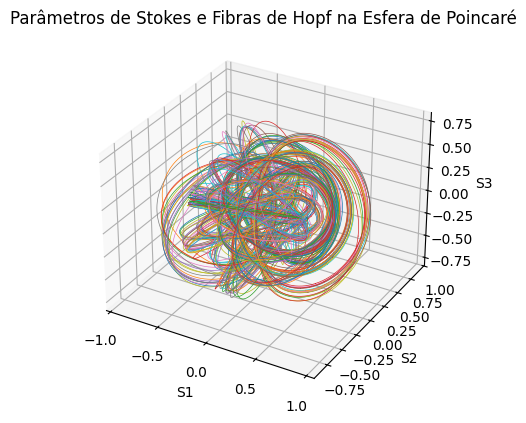

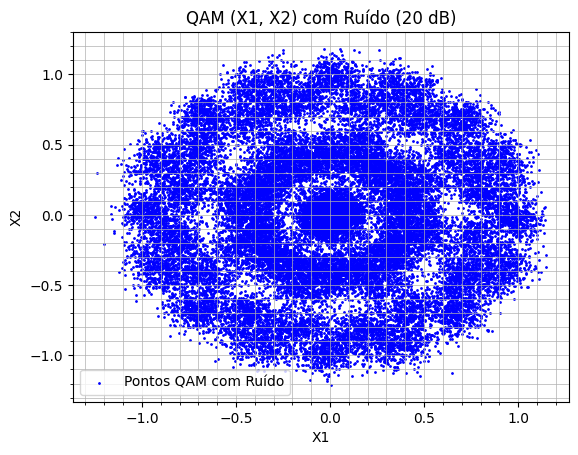

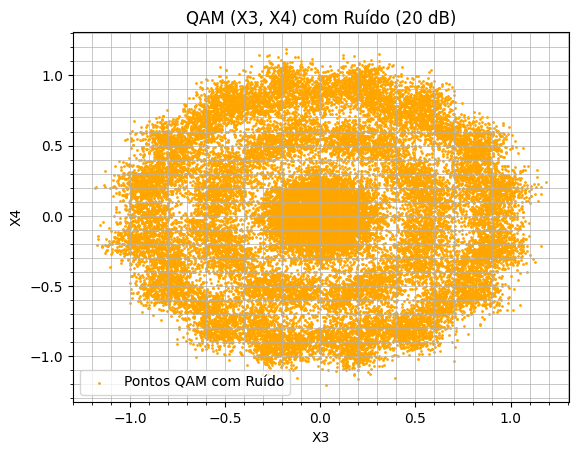

Foram aplicadas 256 iterações de ruído nos pontos QAM.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from matplotlib import colormaps

# Função para mapear a fibriação de Hopf
def hopfmap(a, b, c):
    phi = np.linspace(0, 2 * np.pi, 2001)
    theta = np.arctan2(b, -a) - phi
    alpha = np.sqrt((1 + c) / 2)
    beta = np.sqrt((1 - c) / 2)

    x = beta * np.cos(phi)
    y = beta * np.sin(phi)
    w = alpha * np.cos(theta)
    z = alpha * np.sin(theta)

    r = np.arccos(w) / np.pi

    fx = r / np.sqrt(1 - w**2) * x
    fy = r / np.sqrt(1 - w**2) * y
    fz = r / np.sqrt(1 - w**2) * z

    return fx, fy, fz

# Gerando os pontos ótimos com ruído
m = 16
bits = np.random.randint(0, 2, 1024)

phi = []
E_x = []
E_y = []
S0 = []
S1 = []
S2 = []
S3 = []

# Mapeamento de bits para valores E_x, E_y e phi
for i in range(0, len(bits), 4):
    bits_entrada = bits[i:i+4]

    if np.array_equal(bits_entrada, [0,0,0,0]):
        E_x.append(0.8225)
        phi0 = 36.73 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.5688 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [0,0,0,1]):
        E_x.append(0.5518)
        phi0 = 123.61 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8340 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [0,0,1,0]):
        E_x.append(0.9009)
        phi0 = -85.85 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4339 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [0,0,1,1]):
        E_x.append(0.2519)
        phi0 = -71.99 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.9677 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [0,1,0,0]):
        E_x.append(0.7894)
        phi0 = -146.75 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.6138 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [0,1,0,1]):
        E_x.append(0.5969)
        phi0 = -106.38 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8023 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [0,1,1,0]):
        E_x.append(0.5010)
        phi0 = 6.08 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8654 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [0,1,1,1]):
        E_x.append(0.1938)
        phi0 = -94.74 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.9810 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,0,0,0]):
        E_x.append(0.8730)
        phi0 = 101.69 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.4877 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,0,0,1]):
        E_x.append(0.9845)
        phi0 = 17.60 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.1754 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,0,1,0]):
        E_x.append(0.7729)
        phi0 = 161.49 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.6346 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,0,1,1]):
        E_x.append(0.4186)
        phi0 = -168.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.9082 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,1,0,0]):
        E_x.append(0.8381)
        phi0 = -18.04 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.5455 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,1,0,1]):
        E_x.append(0.9642)
        phi0 = -177.78 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.2651 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,1,1,0]):
        E_x.append(0.6292)
        phi0 = -54.37 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.7772 * np.exp(1j * phi0))

    elif np.array_equal(bits_entrada, [1,1,1,1]):
        E_x.append(0.5866)
        phi0 = 69.94 * np.pi / 180
        phi.append(phi0)
        E_y.append(0.8099 * np.exp(1j * phi0))

# Adição de ruído
SNR = 20  # dB
SNR_Lin = 10**(SNR / 10)
Pn = 1 / SNR_Lin
Pnx = Pn / 2
Pny = Pn / 2

E_x = np.array(E_x) + np.sqrt(Pnx / 2) * (np.random.randn(len(E_x)) + 1j * np.random.randn(len(E_x)))
E_y = np.array(E_y) + np.sqrt(Pny / 2) * (np.random.randn(len(E_y)) + 1j * np.random.randn(len(E_y)))

# Cálculo dos parâmetros de Stokes
for i in range(len(E_x)):
    S0.append(abs(E_x[i])**2 + abs(E_y[i])**2)
    S1.append(abs(E_x[i])**2 - abs(E_y[i])**2)
    S2.append(2 * np.real(E_x[i] * np.conj(E_y[i])))
    S3.append(-2 * np.imag(E_x[i] * np.conj(E_y[i])))

S0 = np.array(S0)
S1 = np.array(S1)
S2 = np.array(S2)
S3 = np.array(S3)

# Normalização dos parâmetros de Stokes
S0n = S0 / S0
S1n = S1 / S0
S2n = S2 / S0
S3n = S3 / S0

# QAM Points
X1 = []
X2 = []
X3 = []
X4 = []

varphi_vals = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi, 5*np.pi/4, 3*np.pi/2, 7*np.pi/4]

# Definindo os valores de theta e phi
theta_vals = [
    1.1309473219902706,
   -2.2255423668667524,
    0.09038507848899477,
    2.970673346448208,
   -1.2756648241792479,
   -2.387215925547989,
    2.094526307990567,
    3.1079800611023316,
   -0.3179112517319884,
    0.3372679757158969,
   -1.364546691910296,
   -2.287020803647047,
    1.1351770152612488,
   -0.5363541333674995,
    1.9212147289532677,
    2.326946685999672
]

phi_vals = [
   -0.5938893743853481,
   -0.8735633617451225,
    0.8944662742847747,
    0.4821584467390801,
    0.5601647742015053,
    1.1653645222111482,
   -0.09183019350017553,
   -0.3887055653851591,
   -0.9861887713832163,
   -0.10459119291955589,
   -0.3166781970833945,
    0.14632728912079954,
    0.2871269180440827,
    0.01970151819224032,
    0.9188159494698991,
   -1.098891916765288
]


count = 0
for n in range(len(theta_vals)):
    theta = theta_vals[n]
    phi = phi_vals[n]
    for varphi in varphi_vals:
        count += 1
        X1.append(np.round(np.cos(theta / 2) * np.cos(varphi + phi / 2), 4))
        X2.append(np.round(np.cos(theta / 2) * np.sin(varphi + phi / 2), 4))
        X3.append(np.round(np.sin(theta / 2) * np.cos(varphi - phi / 2), 4))
        X4.append(np.round(np.sin(theta / 2) * np.sin(varphi - phi / 2), 4))

print(f'\n\nForam realizadas {count} operações\n\n')

#esse pedaço ignora os pontos (0,0)
# count = 0
# for n in range(len(theta_vals)):
#     theta = theta_vals[n]
#     phi = phi_vals[n]
#     for varphi in varphi_vals:
#         count += 1
#         x1 = np.round(np.cos(theta / 2) * np.cos(varphi + phi / 2), 4)
#         x2 = np.round(np.cos(theta / 2) * np.sin(varphi + phi / 2), 4)
#         x3 = np.round(np.sin(theta / 2) * np.cos(varphi - phi / 2), 4)
#         x4 = np.round(np.sin(theta / 2) * np.sin(varphi - phi / 2), 4)

#         # Apenas adiciona se não for (0, 0)
#         if not (x1 == 0 and x2 == 0):
#             X1.append(x1)
#             X2.append(x2)
#         if not (x3 == 0 and x4 == 0):
#             X3.append(x3)
#             X4.append(x4)

# print(f'\n\nForam realizadas {count} operações\n')
# print(f'{len(X1)} pontos válidos em (X1, X2)')
# print(f'{len(X3)} pontos válidos em (X3, X4)\n')

# Visualização na Esfera de Poincaré
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Adicionando as fibras de Hopf
for i in range(len(S1n)):
    fx, fy, fz = hopfmap(S1n[i], S2n[i], S3n[i])
    ax.plot3D(fx, fy, fz, linewidth=0.5)

ax.set_xlabel('S1')
ax.set_ylabel('S2')
ax.set_zlabel('S3')
plt.title('Parâmetros de Stokes e Fibras de Hopf na Esfera de Poincaré')
plt.show()

# Configuração do SNR para os pontos QAM

SNR_QAM_Lin = 10**(SNR / 10)
Pn_QAM = 1 / SNR_QAM_Lin
sigma_QAM = np.sqrt(Pn_QAM / 2)  # Desvio padrão do ruído QAM

# Variáveis para os pontos QAM com ruído (em várias instâncias)
X1_noisy = []
X2_noisy = []
X3_noisy = []
X4_noisy = []

# Aplicar ruído iterativamente o mesmo número de vezes que na modulação 8PolSK
num_iteracoes = len(S1n)  # Número de fibras de Hopf geradas

for _ in range(num_iteracoes):
    # Adicionando ruído aos pontos QAM
    X1_noisy.append(np.array(X1) + sigma_QAM * (np.random.randn(len(X1)) + 1j * np.random.randn(len(X1))))
    X2_noisy.append(np.array(X2) + sigma_QAM * (np.random.randn(len(X2)) + 1j * np.random.randn(len(X2))))
    X3_noisy.append(np.array(X3) + sigma_QAM * (np.random.randn(len(X3)) + 1j * np.random.randn(len(X3))))
    X4_noisy.append(np.array(X4) + sigma_QAM * (np.random.randn(len(X4)) + 1j * np.random.randn(len(X4))))

# Combinar os resultados de todas as iterações para visualização conjunta
X1_noisy_combined = np.hstack(X1_noisy).real
X2_noisy_combined = np.hstack(X2_noisy).real
X3_noisy_combined = np.hstack(X3_noisy).real
X4_noisy_combined = np.hstack(X4_noisy).real

# Visualização dos pontos QAM dispersos pelo ruído
plt.figure(1)
plt.scatter(X1_noisy_combined, X2_noisy_combined, color='b', s=1, label='Pontos QAM com Ruído')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()
plt.title('QAM (X1, X2) com Ruído (20 dB)')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()

plt.figure(2)
plt.scatter(X3_noisy_combined, X4_noisy_combined, color='orange', s=1, label='Pontos QAM com Ruído')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
plt.minorticks_on()
plt.title('QAM (X3, X4) com Ruído (20 dB)')
plt.xlabel('X3')
plt.ylabel('X4')
plt.legend()

plt.show()

# Exibindo a quantidade de iterações realizadas
print(f"Foram aplicadas {num_iteracoes} iterações de ruído nos pontos QAM.")